# Store Sales Forecasting: EDA, Leakage-Safe ML Pipeline & XGBoost

**Dataset:** Kaggle *Store Sales – Time Series Forecasting* (Corporación Favorita, Ecuador), supplied as `store-sales-time-series-forecasting.zip`.

This notebook runs the whole workflow, from the raw ZIP to a validated `submission.csv`. The reusable logic lives in `../src/`, and this notebook orchestrates it, displays the results and interprets them.

## 1. Project Overview

**Goal:** forecast daily unit sales for each of the 54 stores × 33 product families (1,782 series) for the **16 days** after the last training date (2017-08-16 … 2017-08-31). We also want to understand the business patterns behind those sales.

**Approach in one paragraph:** We audit data quality and explore the data. We then build features that are known at forecast time: calendar, holidays, promotions, store metadata, and sales/transactions/oil history. Every model is evaluated with the same **rolling-origin, 16-day multi-step protocol**, in which the model never sees actual sales after the forecast origin. The models compared are four baselines, a Decision Tree, a Random Forest, XGBoost (baseline config, tuned config, a *direct* 16-day-lag variant and feature-group ablations) and AutoGluon Tabular. The final model is chosen from the evaluation folds and retrained on all data up to 2017-08-15, and it produces the test forecast.

| Item | Choice |
|---|---|
| Prediction unit | one (date, store_nbr, family) row |
| Target | `sales`, modelled as `log1p(sales)` (matches the RMSLE competition metric) |
| Horizon | 16 days, multi-step (recursive or direct) |
| Validation | 3 expanding-window folds of 16 days each: F1 = tuning only, F2 + F3 = reported evaluation |
| Primary metric | RMSLE (also MAE, RMSE, WAPE, bias) |

## 2. Environment Setup

Configuration lives in one place. Set `QUICK_TEST = True` (or the environment variable `STORE_SALES_QUICK_TEST=1`) to get a fast smoke run. Quick mode uses all series but a short history and tiny searches, and writes to `outputs/quick_test/` so it can never overwrite full-run results.

In [1]:
import os, sys, time, json, random, warnings, platform, importlib, importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# ---------------- configuration ----------------
QUICK_TEST = os.environ.get("STORE_SALES_QUICK_TEST", "0") == "1"   # set True for a fast smoke test
RANDOM_STATE = 42
RUN_AUTOGLUON = True          # skipped automatically (with a message) if AutoGluon is not installed
N_JOBS = os.cpu_count() or 1

# project root = folder that contains src/ (works from notebooks/ or from the root)
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
DATA_DIR = Path(os.environ.get("STORE_SALES_DATA_DIR", PROJECT_ROOT / "data"))
ZIP_CANDIDATES = [DATA_DIR / "store-sales-time-series-forecasting.zip",
                  PROJECT_ROOT / "store-sales-time-series-forecasting.zip"]
OUTPUT_DIR = PROJECT_ROOT / "outputs"
MODEL_DIR = PROJECT_ROOT / "models"

if QUICK_TEST:
    OUTPUT_DIR, MODEL_DIR = OUTPUT_DIR / "quick_test", MODEL_DIR / "quick_test"
    TRAIN_START = "2017-04-01"                       # ~4.5 months of training rows
    DT_GRID = [dict(max_depth=10, min_samples_leaf=50)]
    RF_GRID = [dict(n_estimators=20, max_depth=14, min_samples_leaf=20, max_features=0.5, max_samples=0.3)]
    XGB_SEARCH_N, XGB_MAX_ROUNDS, AG_TIME_LIMIT = 2, 300, 120
    RUN_ABLATIONS = False
else:
    TRAIN_START = "2016-01-01"                       # ~19.5 months of training rows per fold
    DT_GRID = [dict(max_depth=d, min_samples_leaf=l) for d in (10, 14, 18) for l in (50, 200)]
    RF_GRID = [dict(n_estimators=100, max_depth=18, min_samples_leaf=20, max_features=0.5, max_samples=0.15),
               dict(n_estimators=100, max_depth=24, min_samples_leaf=10, max_features=0.33, max_samples=0.15)]
    XGB_SEARCH_N, XGB_MAX_ROUNDS, AG_TIME_LIMIT = 6, 1200, 480
    RUN_ABLATIONS = True

FIG_DIR = OUTPUT_DIR / "figures"
for d in (DATA_DIR, OUTPUT_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(RANDOM_STATE)   # all numpy/sklearn/xgboost randomness uses explicit RANDOM_STATE / Generator objects
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
%matplotlib inline
plt.rcParams["figure.dpi"] = 90

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from data_validation import extract_dataset, load_data, describe_tables, validate_data, preprocess_data
from feature_engineering import (build_features, build_training_frame, masked_history, get_feature_columns,
                                 feature_groups, history_cols, CAT_COLS, PROMO_COLS, EXTERNAL_COLS, HORIZON)
from train import (create_time_splits, test_fold, regression_metrics, actuals_for, forecast, train_baselines,
                   run_model, train_models, evaluate_models, compare_models, fit_sklearn, fit_xgboost,
                   fit_autogluon, ExperimentLog, FrameCache, zero_series_mask)
from predict import generate_predictions, validate_submission, save_artifacts
import eda

def pkg_version(name):
    try:
        return importlib.import_module(name).__version__
    except ImportError as exc:
        return f"not installed ({exc.name})"

versions = {"python": platform.python_version(), **{m: pkg_version(m) for m in
            ["pandas", "numpy", "sklearn", "xgboost", "shap", "matplotlib", "seaborn", "joblib", "autogluon.tabular"]}}
print(f"MODE = {'QUICK_TEST (preliminary results)' if QUICK_TEST else 'FULL TRAINING'} | cores = {N_JOBS}")
print(f"PROJECT_ROOT = {PROJECT_ROOT}\nTRAIN_START = {TRAIN_START}")
display(pd.Series(versions, name="version").to_frame())
RUN_T0 = time.time()

MODE = FULL TRAINING | cores = 2
PROJECT_ROOT = /home/claude/store-sales-forecasting
TRAIN_START = 2016-01-01


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,version
python,3.13.16
pandas,2.3.3
numpy,2.5.3
sklearn,1.9.1
xgboost,3.4.1
shap,0.54.1
matplotlib,3.11.2
seaborn,0.13.2
joblib,1.6.0
autogluon.tabular,1.6.3


## 3. Dataset Extraction and Loading

The ZIP is extracted into `DATA_DIR`; files that already exist are skipped. We list the archive members before reading anything.

In [2]:
import zipfile
zip_path = next((p for p in ZIP_CANDIDATES if p.exists()), None)
if zip_path is not None:
    with zipfile.ZipFile(zip_path) as zf:
        display(pd.DataFrame([(i.filename, i.file_size / 1e6) for i in zf.infolist()], columns=["file", "size_MB"]))
    extract_dataset(zip_path, DATA_DIR)
elif not (DATA_DIR / "train.csv").exists():
    raise FileNotFoundError(f"Put store-sales-time-series-forecasting.zip in {DATA_DIR} or {PROJECT_ROOT}, "
                            "or set STORE_SALES_DATA_DIR to a folder containing the extracted CSVs.")
else:
    print(f"ZIP not found; using already-extracted CSVs in {DATA_DIR}")

t0 = time.time()
raw = load_data(DATA_DIR)
print(f"Loaded {len(raw)} tables in {time.time()-t0:.1f}s")
display(describe_tables(raw))

ZIP not found; using already-extracted CSVs in /home/claude/store-sales-forecasting/data


Loaded 7 tables in 1.8s


,table,rows,cols,columns,memory_mb,date_min,date_max,n_dates
0,train,3000888,6,"id, date, store_nbr, family, sales, onpromotion",123.0400,2013-01-01,2017-08-15,"1,684.0000"
1,test,28512,5,"id, date, store_nbr, family, onpromotion",0.9400,2017-08-16,2017-08-31,16.0000
2,stores,54,5,"store_nbr, city, state, type, cluster",0.0000,NaN,NaN,NaN
3,oil,1218,2,"date, dcoilwtico",0.0200,2013-01-01,2017-08-31,"1,218.0000"
4,holidays_events,350,6,"date, type, locale, locale_name, description, ...",0.0300,2012-03-02,2017-12-26,312.0000
5,transactions,83488,3,"date, store_nbr, transactions",2.0000,2013-01-01,2017-08-15,"1,682.0000"
6,sample_submission,28512,2,"id, sales",0.4600,NaN,NaN,NaN


## 4. Data Understanding

We check schemas, samples, the target and the prediction unit, the date ranges and frequency, identifier validity, and whether each merge key is safe to join on.

In [3]:
for name, df in raw.items():
    print(f"=== {name}: {df.shape[0]:,} rows x {df.shape[1]} cols, {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
    display(pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(), "n_missing": df.isna().sum()}).T)
    display(df.head(3))

=== train: 3,000,888 rows x 6 cols, 123.0 MB


,id,date,store_nbr,family,sales,onpromotion
dtype,int64,datetime64[ns],int64,category,float64,int64
n_unique,3000888,1684,54,33,379610,362
n_missing,0,0,0,0,0,0


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0000,0
1,1,2013-01-01,1,BABY CARE,0.0000,0
2,2,2013-01-01,1,BEAUTY,0.0000,0


=== test: 28,512 rows x 5 cols, 0.9 MB


,id,date,store_nbr,family,onpromotion
dtype,int64,datetime64[ns],int64,category,int64
n_unique,28512,16,54,33,212
n_missing,0,0,0,0,0


...

,date,store_nbr,transactions
dtype,datetime64[ns],int64,int64
n_unique,1682,54,4993
n_missing,0,0,0


,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358


=== sample_submission: 28,512 rows x 2 cols, 0.5 MB


,id,sales
dtype,int64,float64
n_unique,28512,1
n_missing,0,0


,id,sales
0,3000888,0.0000
1,3000889,0.0000
2,3000890,0.0000


In [4]:
tr, te = raw["train"], raw["test"]
n_stores, n_fam = tr["store_nbr"].nunique(), tr["family"].nunique()
summary = {
    "target": "sales (units; float, some families sold by weight)",
    "prediction unit": "(date, store_nbr, family)",
    "stores x families": f"{n_stores} x {n_fam} = {n_stores*n_fam} series",
    "train dates": f"{tr['date'].min().date()} .. {tr['date'].max().date()} ({tr['date'].nunique()} distinct days)",
    "test dates": f"{te['date'].min().date()} .. {te['date'].max().date()} ({te['date'].nunique()} days)",
    "frequency": f"daily; median gap between distinct dates = {pd.Series(np.sort(tr['date'].unique())).diff().median()}",
    "rows per train date (min/max)": f"{tr.groupby('date').size().min()} / {tr.groupby('date').size().max()}",
    "test rows = series x days": f"{len(te)} = {te.groupby(['store_nbr','family'], observed=True).ngroups} x {te['date'].nunique()}",
    "train id range": f"{tr['id'].min()} .. {tr['id'].max()} (unique={tr['id'].is_unique})",
    "test id range": f"{te['id'].min()} .. {te['id'].max()} (unique={te['id'].is_unique})",
}
display(pd.Series(summary, name="value").to_frame())

,value
target,"sales (units; float, some families sold by wei..."
prediction unit,"(date, store_nbr, family)"
stores x families,54 x 33 = 1782 series
train dates,2013-01-01 .. 2017-08-15 (1684 distinct days)
test dates,2017-08-16 .. 2017-08-31 (16 days)
frequency,daily; median gap between distinct dates = 1 d...
rows per train date (min/max),1782 / 1782
test rows = series x days,28512 = 1782 x 16
train id range,0 .. 3000887 (unique=True)
test id range,3000888 .. 3029399 (unique=True)


**Merge-key validation.** `stores` (key `store_nbr`), `oil` (key `date`) and `transactions` (key `date, store_nbr`) each have unique keys. `holidays_events` does **not**: several dates have more than one record. The cell below measures how many rows a naive join would add.

In [5]:
hol = raw["holidays_events"]
key_checks = pd.DataFrame([
    ("stores", "store_nbr", raw["stores"]["store_nbr"].is_unique),
    ("oil", "date", raw["oil"]["date"].is_unique),
    ("transactions", "date, store_nbr", not raw["transactions"].duplicated(["date", "store_nbr"]).any()),
    ("holidays_events", "date", hol["date"].is_unique),
], columns=["table", "key", "key_unique"])
display(key_checks)
naive = tr[["date"]].merge(hol[["date"]], on="date", how="left")
print(f"Naive train x holidays join on date: {len(tr):,} -> {len(naive):,} rows "
      f"(+{len(naive)-len(tr):,} duplicated rows). We therefore aggregate holidays to one row per key before joining.")
display(hol[hol["date"].duplicated(keep=False)].sort_values("date").head(8))

,table,key,key_unique
0,stores,store_nbr,True
1,oil,date,True
2,transactions,"date, store_nbr",True
3,holidays_events,date,False


Naive train x holidays join on date: 3,000,888 -> 3,054,348 rows (+53,460 duplicated rows). We therefore aggregate holidays to one row per key before joining.


,date,type,locale,locale_name,description,transferred
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura,False
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga,False
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala,False
10,2012-07-03,Holiday,Local,Santo Domingo,Fundacion de Santo Domingo,False
11,2012-07-03,Holiday,Local,El Carmen,Cantonizacion de El Carmen,False
32,2012-12-22,Holiday,Local,Salinas,Cantonizacion de Salinas,False
33,2012-12-22,Additional,National,Ecuador,Navidad-3,False
36,2012-12-24,Additional,National,Ecuador,Navidad-1,False


**Assumptions taken from the data (verified above):**
1. Each (store, family) pair forms one daily series. All 1,782 pairs appear in both train and test, so there is no cold start.
2. The test set covers exactly the 16 days after the last training date, with no gap.
3. `onpromotion` is supplied for the test period, so it is treated as known in advance (a planned promotion).
4. `oil.csv` contains prices for the test period, and `transactions.csv` stops at 2017-08-15. Neither would be known at a real forecast origin, so both are used **only with a lag of 16 days or more**.
5. `transferred=True` holidays were celebrated on another date (the matching `Transfer` row), so they are not treated as days off.
6. Information from the competition description, *not* from the files: public-sector wages are paid on the 15th and on the last day of each month. This is used as an `is_payday` feature and labelled as such.

## 5. Data Quality Assessment

`validate_data()` runs every check and records its magnitude, likely impact and chosen treatment. The report is saved to `outputs/data_quality_report.csv`.

In [6]:
t0 = time.time()
dq = validate_data(raw)
dq.to_csv(OUTPUT_DIR / "data_quality_report.csv", index=False)
print(f"{len(dq)} checks in {time.time()-t0:.1f}s -> {OUTPUT_DIR / 'data_quality_report.csv'}")
with pd.option_context("display.max_colwidth", 120):
    display(dq)

43 checks in 5.1s -> /home/claude/store-sales-forecasting/outputs/data_quality_report.csv


,table,check,magnitude,impact,treatment
0,train,missing values,none,-,none needed
1,test,missing values,none,-,none needed
2,stores,missing values,none,-,none needed
3,oil,missing values,dcoilwtico=43 (3.5%),oil gaps break joins/lag features,oil: forward-fill then back-fill on a full daily calendar
4,holidays_events,missing values,none,-,none needed
5,transactions,missing values,none,-,none needed
6,sample_submission,missing values,none,-,none needed
7,train,fully duplicated rows,0,-,none needed
8,test,fully duplicated rows,0,-,none needed
9,stores,fully duplicated rows,0,-,none needed


**Data-quality findings (from the report above):**
* **Missing values.** The only gaps are in `oil.dcoilwtico`: 43 values (3.5%). Oil is forward-filled on a daily calendar and is only used with a lag of 16 days or more.
* **Duplicates.** There are no duplicate rows or duplicate business keys in train, test, stores, oil or transactions. `holidays_events` has **38 dates with more than one record**, and a naive join on `date` would add **53,460 duplicate train rows**. Holidays are therefore aggregated to one flag per key before joining.
* **Target.** There are no negative sales. **31.3% of rows are zero.** 53 series never sell anything, and 8 stores open late (20, 21, 22, 29, 36, 42, 52, 53), which produces structural leading zeros. These zeros are genuine information, so they are kept. 15.4% of sales values are non-integer (families sold by weight).
* **Outliers.** 6,226 series-days are robust-z > 10 spikes within their series. They line up with events such as the 2016 earthquake, promotions and holidays, so they are kept, and the log1p target dampens their influence. The crude global IQR rule flags 9.2% of positive rows only because family scales differ, not because the values are errors.
* **Time coverage.** Four calendar dates are missing (every Dec 25, when stores are closed). They are re-indexed as NaN targets. Every present date has all 1,782 series.
* **Leakage risks.** Oil covers the test period but would not be known at forecast time. Transactions stop at the last train date, and 8.4% of store-days are missing. Both sources are used with a lag of 16 days or more only.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

## 6. Exploratory Data Analysis

Each subsection states the question it investigates, shows a figure or table, and then gives the finding. Figures are saved to `outputs/figures/`.

In [7]:
trm = eda.merged_train(raw)   # train + store metadata (one row per train row; validated many-to-one)
assert len(trm) == len(raw["train"])

### 6.1 Overall sales
**Questions:** How does total sales evolve? What does the target distribution look like, and how common are zeros?

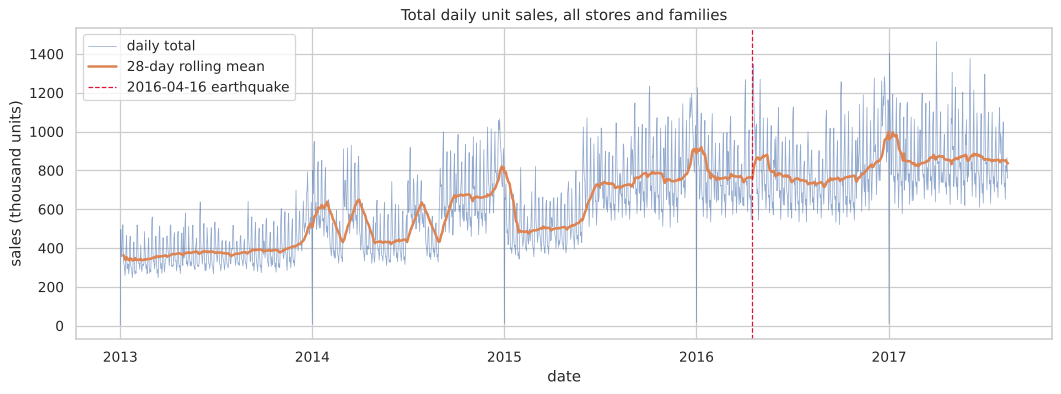

,value
rows,"3,000,888.0000"
mean,357.7757
median,11.0000
std,"1,101.9977"
q25,0.0000
q75,195.8473
q95,"1,965.0000"
q99,"5,507.0000"
max,"124,717.0000"
skewness,7.3588


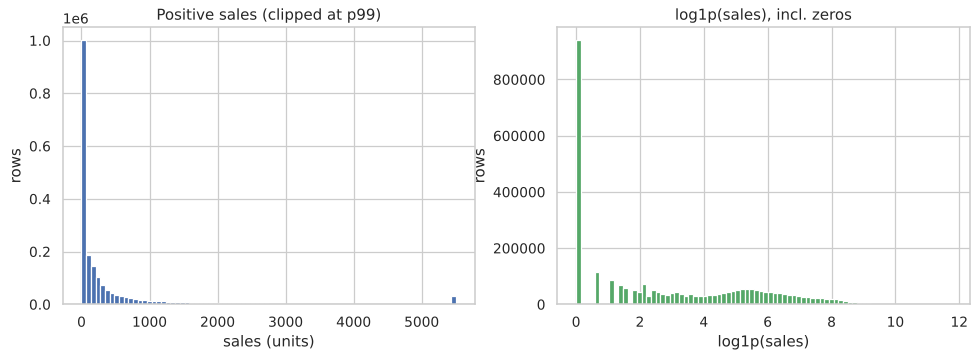

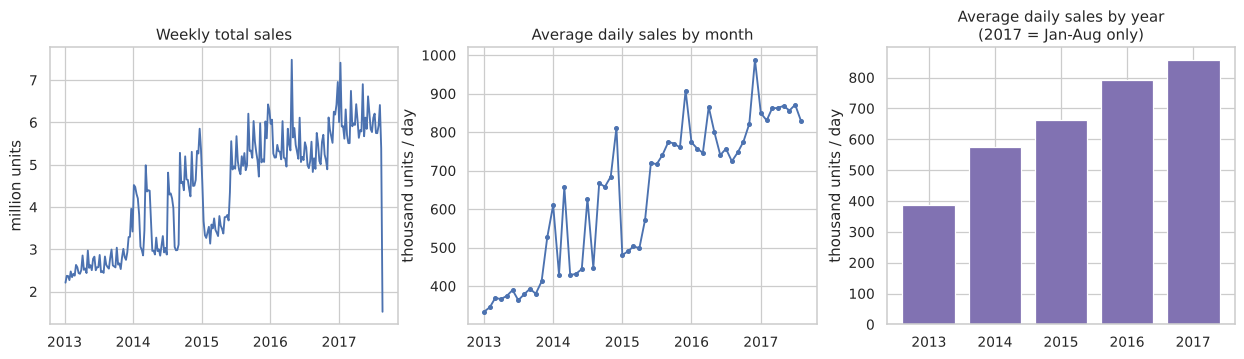

,mean,count,yoy_growth
date,,,
2013,"385,766.5218",364,NaN
2014,"575,478.6986",364,0.4918
2015,"661,758.5183",364,0.1499
2016,"790,834.3095",365,0.1950
2017,"855,581.7990",227,0.0819


Avg daily total 28d before earthquake: 761,229; 14d after: 922,942 (+21.2%)
Lowest daily totals:
 date
2013-01-01     2,512.0000
2014-01-01     8,602.0000
2017-01-01    12,083.0000
2015-01-01    12,774.0000
2016-01-01    16,433.0000
2013-01-24   247,246.0000


/tmp/ipykernel_1761/1799888993.py:7: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pre = daily_total[(idx >= eq - pd.Timedelta(days=28)) & (idx < eq)].mean()
/tmp/ipykernel_1761/1799888993.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  post = daily_total[(idx >= eq) & (idx < eq + pd.Timedelta(days=14))].mean()


In [8]:
daily_total = eda.plot_total_sales(trm, FIG_DIR); plt.show()
display(eda.sales_distribution(trm, FIG_DIR)); plt.show()
yearly = eda.plot_periodic_trends(trm, FIG_DIR); plt.show()
display(yearly)
eq = pd.Timestamp("2016-04-16")
idx = daily_total.index
pre = daily_total[(idx >= eq - pd.Timedelta(days=28)) & (idx < eq)].mean()
post = daily_total[(idx >= eq) & (idx < eq + pd.Timedelta(days=14))].mean()
print(f"Avg daily total 28d before earthquake: {pre:,.0f}; 14d after: {post:,.0f} ({post/pre-1:+.1%})")
low = daily_total.nsmallest(6); print("Lowest daily totals:\n", low.round(0).to_string())

**Findings: overall sales**
* Volume grows strongly. Average daily units rose from 386k (2013) to 576k (2014, +49%), 662k (2015, +15%), 791k (2016, +20%) and 856k (Jan–Aug 2017, +8%). **Implication:** level features (rolling means) matter more than long-memory features. Models should be trained on recent data (we start at 2016-01-01).
* The target is **extremely right-skewed**: mean 358 vs median 11, skewness 7.4, kurtosis 155, and 31% zeros. **Implication:** we model `log1p(sales)`, which also optimises RMSLE directly.
* **Structural events.** In the 14 days after the 2016-04-16 earthquake, daily sales averaged 21% above the preceding 28 days (relief purchases). Every Jan 1 is near zero (2.5k–16k units vs. 700k+ normally). **Implication:** we use holiday/event flags, which include the earthquake "Terremoto Manabi" events, and we do not delete these days.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

### 6.2 Stores and product families
**Questions:**   How do store type, cluster and city differ? Which families are most volatile?

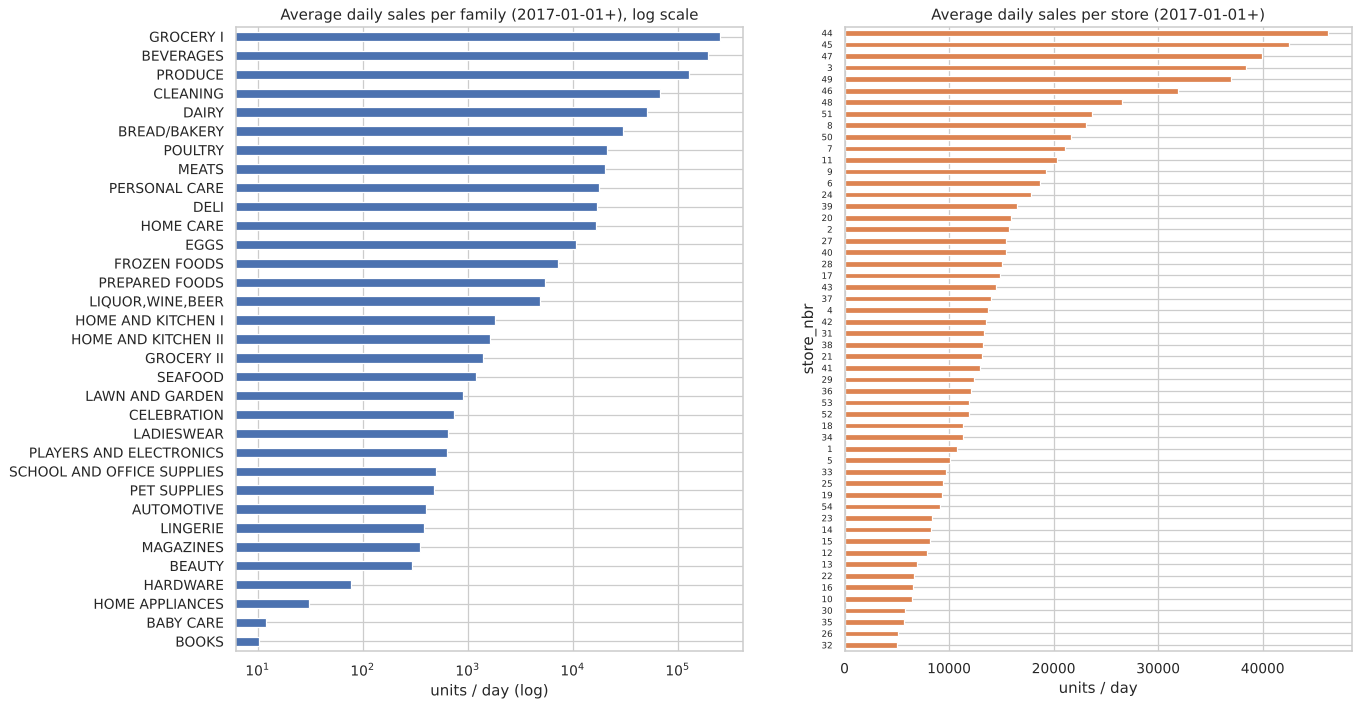

Top 5 stores (2017 avg daily units):


,store_nbr,type,cluster,city,avg_daily_sales
53,44,A,5,Quito,"46,211.9823"
52,45,A,11,Quito,"42,537.0983"
51,47,A,14,Quito,"39,952.0634"
50,3,D,8,Quito,"38,380.3540"
49,49,A,11,Quito,"36,935.0153"


Bottom 5 stores:


,store_nbr,type,cluster,city,avg_daily_sales
0,32,C,3,Guayaquil,"4,980.7990"
1,26,D,10,Guayaquil,"5,123.7755"
2,35,C,3,Playas,"5,662.2528"
3,30,C,3,Guayaquil,"5,754.2636"
4,10,C,15,Quito,"6,441.7300"


Top-5 family share of 2017 volume: {'GROCERY I': 0.294, 'BEVERAGES': 0.226, 'PRODUCE': 0.151, 'CLEANING': 0.08, 'DAIRY': 0.059} -> cumulative 81.0%


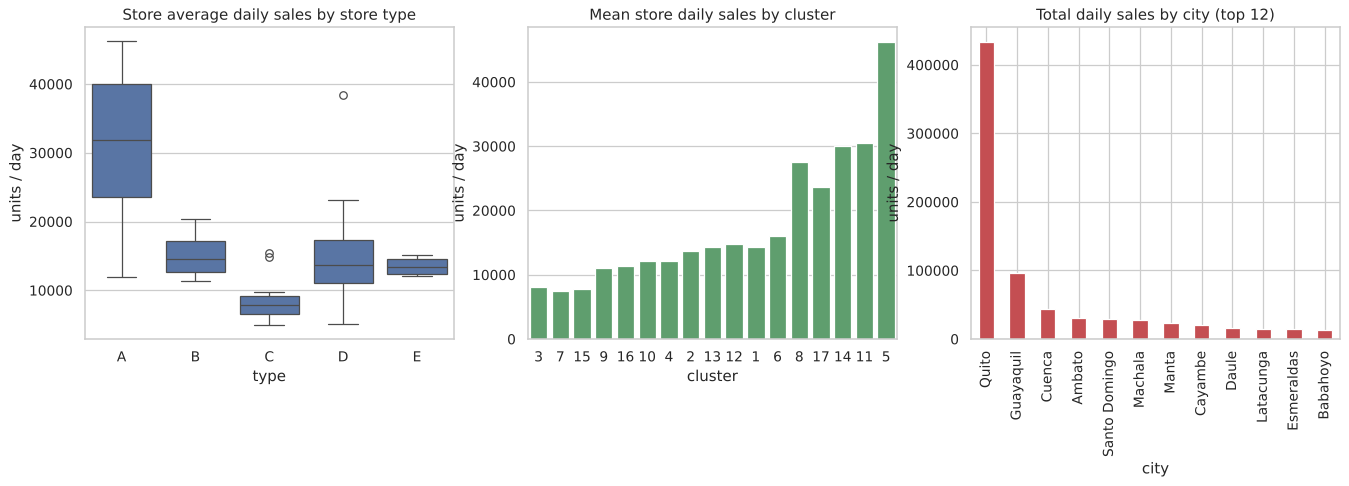

,count,mean,median
type,,,
A,9,"31,242.5656","31,882.4852"
D,18,"15,194.5199","13,638.5944"
B,8,"15,142.0593","14,606.1004"
E,4,"13,509.0202","13,428.3037"
C,15,"8,381.6530","7,903.5779"


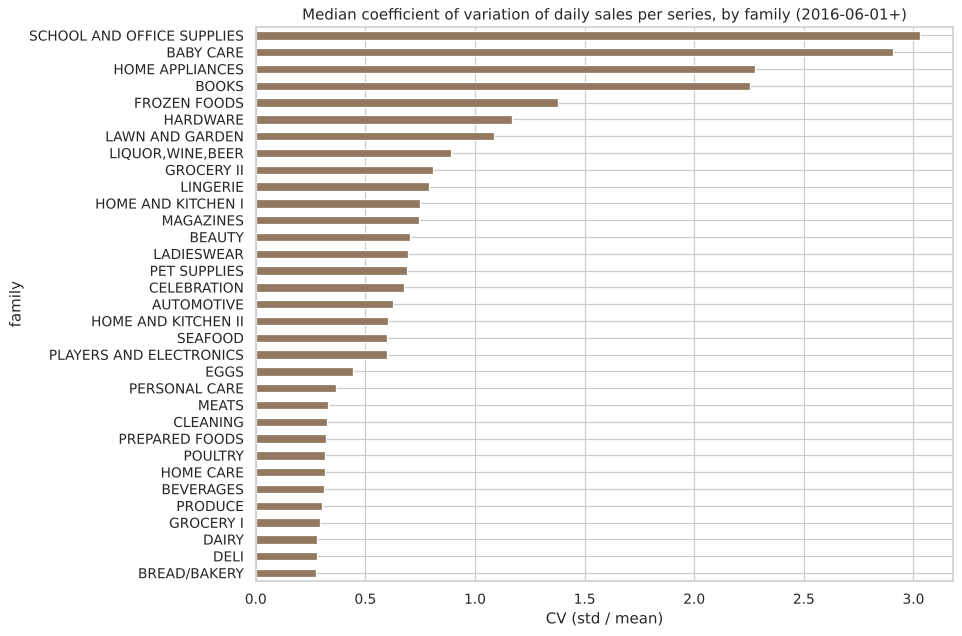

,family,median_cv
27,HARDWARE,1.1674
28,FROZEN FOODS,1.3797
29,BOOKS,2.2530
30,HOME APPLIANCES,2.2762
31,BABY CARE,2.9055
32,SCHOOL AND OFFICE SUPPLIES,3.0302


In [9]:
by_store, by_family = eda.store_family_summary(trm, FIG_DIR); plt.show()
print("Top 5 stores (2017 avg daily units):"); display(by_store.sort_values("avg_daily_sales", ascending=False).head(5))
print("Bottom 5 stores:"); display(by_store.head(5))
fam_share = (by_family.set_index("family")["avg_daily_sales"] / by_family["avg_daily_sales"].sum()).sort_values(ascending=False)
print("Top-5 family share of 2017 volume:", fam_share.head(5).round(3).to_dict(), f"-> cumulative {fam_share.head(5).sum():.1%}")
store_meta = eda.store_meta_summary(trm, FIG_DIR); plt.show()
display(store_meta.groupby("type", observed=True)["avg_daily"].agg(["count", "mean", "median"]).sort_values("mean", ascending=False))
fam_cv = eda.series_variability(trm, FIG_DIR); plt.show()
display(fam_cv.tail(6))

**Findings: stores and families**
* Volume is concentrated. Five families (GROCERY I 29%, BEVERAGES 23%, PRODUCE 15%, CLEANING 8%, DAIRY 6%) make up **81%** of 2017 units, so RMSE/MAE are dominated by them. RMSLE and per-family WAPE give the small families a voice.
* There is a **9×** spread between stores. The top stores (44, 45, 47, 3, 49) are all in Quito, mostly type A, at 37k–46k units/day. The bottom ones (32, 26, 35, 30, 10) sell 5k–6k/day. The type A median (31.9k/day) is about twice that of types B/D and about four times that of type C. **Implication:** store identity, type and cluster carry level information, but per-series rolling means already capture most of it.
* **Volatility is highest in small, intermittent families** (median CV per series: SCHOOL AND OFFICE SUPPLIES 3.0, BABY CARE 2.9, HOME APPLIANCES 2.3, BOOKS 2.3) and lowest in staples (BREAD/BAKERY, DELI, DAIRY ≈ 0.27–0.28). **Implication:** expect high relative error for the intermittent families whatever the model.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

### 6.3 Calendar, seasonality and holidays
**Questions:** How large are the day-of-week and month effects? Which families are seasonal? How do sales behave around holidays and Christmas?

All indices below are *relative* to a 28-day centred rolling mean, which removes trend so that calendar effects are not confounded with growth.

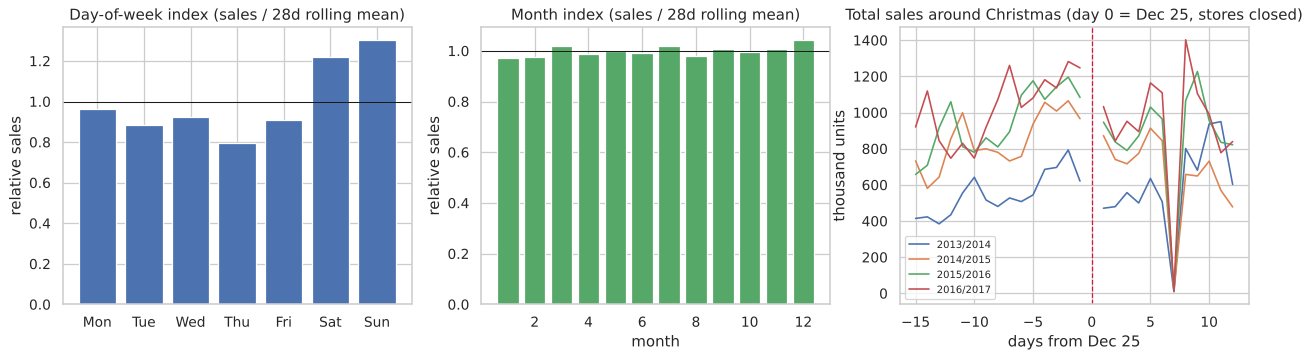

,0,1,2,3,4,5,6,7,8,9,10,11,12
dow_index,0.9638,0.8857,0.9224,0.7936,0.9081,1.2192,1.3014,NaN,NaN,NaN,NaN,NaN,NaN
month_index,NaN,0.9703,0.9769,1.0206,0.9867,1.0007,0.9928,1.0181,0.9787,1.0081,0.9958,1.0077,1.0412


{'weekday': 0.895, 'weekend': 1.26}


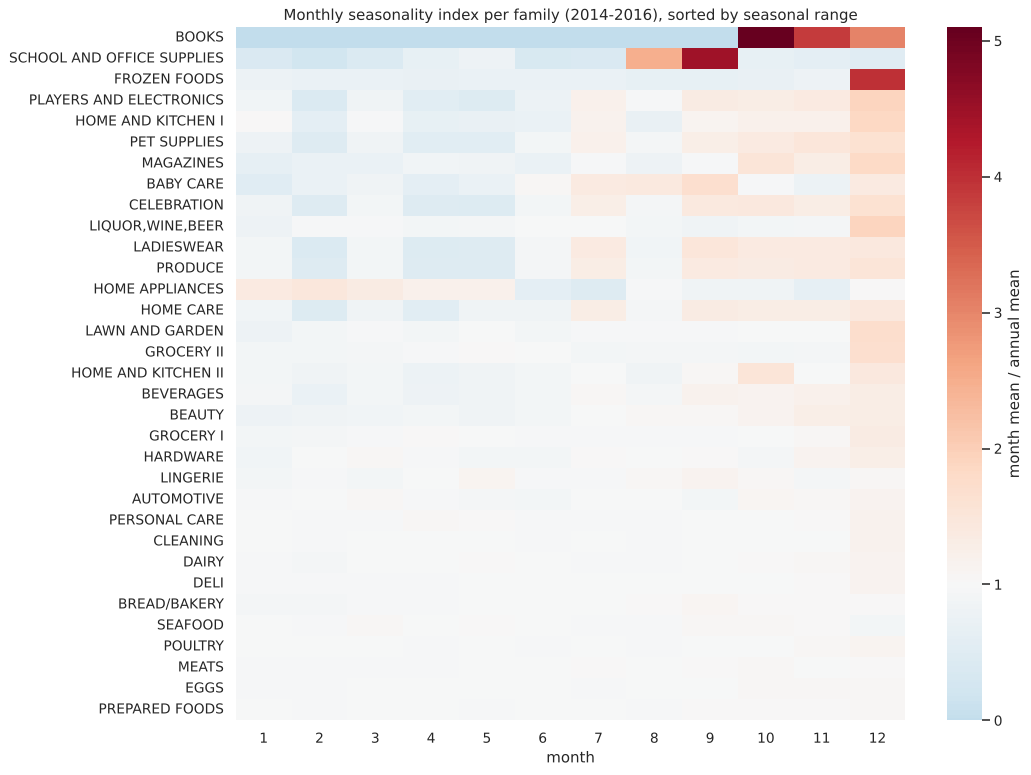

,family,seasonal_range
0,BOOKS,5.0981
1,SCHOOL AND OFFICE SUPPLIES,4.2458
2,FROZEN FOODS,3.2846
3,PLAYERS AND ELECTRONICS,1.5046
4,HOME AND KITCHEN I,1.2564
5,PET SUPPLIES,1.1895
6,MAGAZINES,1.1802
7,BABY CARE,1.1730


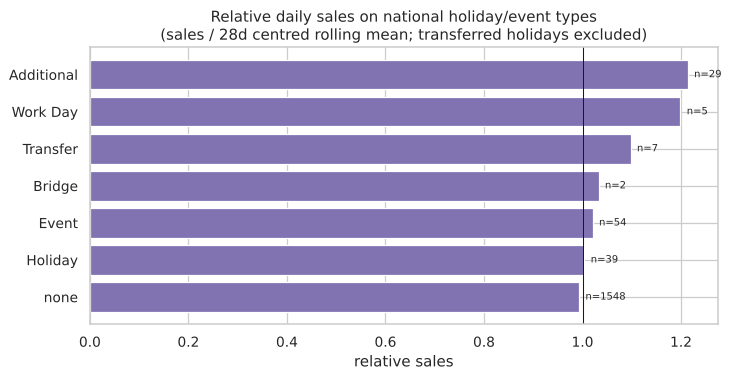

,mean,median,count
primary_type,,,
none,0.9931,0.9207,1548
Holiday,1.0038,1.0770,39
Event,1.0207,0.9840,54
Bridge,1.0327,1.0327,2
Transfer,1.0977,1.0397,7
Work Day,1.1988,1.1812,5
Additional,1.2136,1.2492,29


In [10]:
dow_idx, month_idx, wk = eda.calendar_effects(trm, FIG_DIR); plt.show()
display(pd.concat([dow_idx.T, month_idx.T.rename(index={"month_index": "month_index"})], axis=0))
print(wk.round(3).to_dict())
fam_seas = eda.family_seasonality(trm, FIG_DIR); plt.show()
display(fam_seas.head(8))
hol_summary = eda.holiday_effects(trm, raw, FIG_DIR); plt.show()
display(hol_summary)

**Findings: calendar and holidays**
* The **weekly cycle is the strongest calendar effect.** Relative to the trend, Saturday sits at 1.22 and Sunday at 1.30, while Thursday is the low point at 0.79. Weekends average 1.26 vs. 0.89 on weekdays. **Implication:** lag 7, the same-weekday 4-week mean and day of week are key features. The seasonal-naive and day-of-week-mean baselines are strong for the same reason.
* The month index stays within ±4% of trend (highest in December, 1.04). The index removes a 28-day trend, so it shows within-period deviations only. Annual seasonality is clearer **per family**: BOOKS and SCHOOL AND OFFICE SUPPLIES have huge back-to-school peaks (seasonal range 5.1 and 4.2 × their annual mean), followed by FROZEN FOODS (3.3, December). This matters for the test window (late August), which falls in the school-supplies season.
* **Christmas.** Sales rise through mid-December, stores close on Dec 25, and a second collapse comes on Jan 1.
* **Holiday types.** "Additional" days (mostly around Christmas) average +21% vs. trend, and "Work Day" days (normally a weekend, made working) +20%. Ordinary national "Holiday" days are on average neutral (1.00), and Transfer days +10%. The effect differs by holiday, so the flags are useful but noisy.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

### 6.4 Promotions
**Questions:** How does sales differ with promotion intensity, and across families? How has promotion usage changed over time? *These are observational associations: promotions are targeted at high-volume items and seasons, so they are not causal effects.*

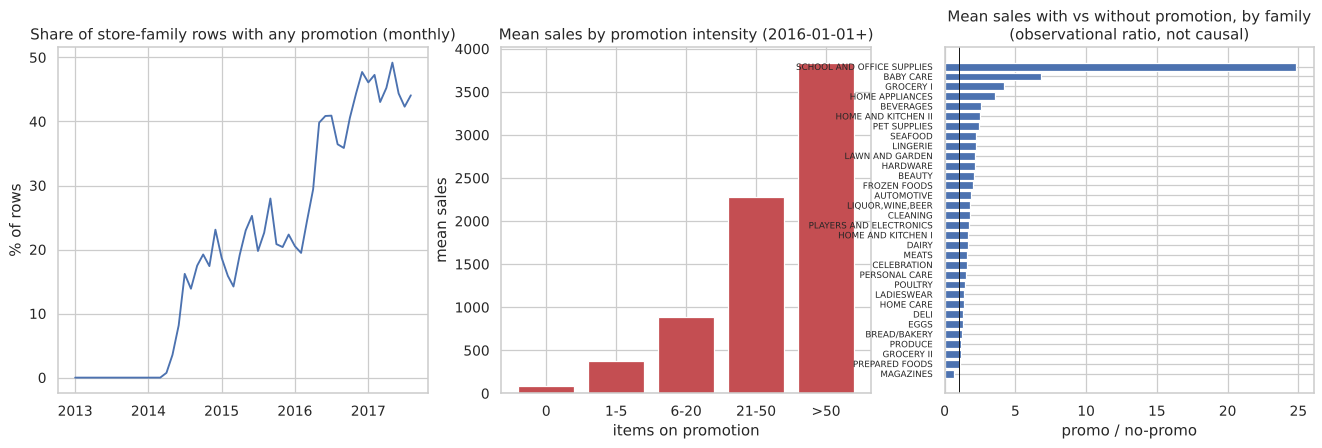

,mean,median,count
promo_bin,,,
0,83.3985,5.0000,643896
1-5,370.3528,113.0000,203669
6-20,884.0025,415.9580,119522
21-50,"2,281.9711","1,595.5000",57124
>50,"3,830.7105","3,165.0000",30733


,no_promo,promo,ratio
family,,,
SCHOOL AND OFFICE SUPPLIES,1.6472,40.9399,24.8541
BABY CARE,0.2449,1.6731,6.8319
GROCERY I,"1,092.5250","4,606.3021",4.2162
HOME APPLIANCES,0.4215,1.4894,3.5331
BEVERAGES,"1,342.8139","3,414.7420",2.5430
HOME AND KITCHEN II,15.4654,39.0785,2.5268


,no_promo,promo,ratio
family,,,
MAGAZINES,6.3619,4.1126,0.6464
PREPARED FOODS,99.9121,108.9042,1.0900
GROCERY II,22.2939,25.9863,1.1656
PRODUCE,"2,033.3573","2,389.6370",1.1752


First date with any onpromotion > 0: 2014-04-01


In [11]:
promo_bins, promo_fam = eda.promotion_effects(trm, FIG_DIR); plt.show()
display(promo_bins)
display(promo_fam.sort_values("ratio", ascending=False).head(6)); display(promo_fam.head(4))
first_promo = raw["train"].loc[raw["train"]["onpromotion"] > 0, "date"].min()
print("First date with any onpromotion > 0:", first_promo.date())

**Findings: promotions** (observational associations, not causal effects)
* Promotions were essentially absent before 2014-04-01, and promotion usage has grown since. Since 2016, 79.6% of rows still have no promotion.
* Mean sales rise monotonically with the number of items on promotion: 83 units (none) → 370 (1–5) → 884 (6–20) → 2,282 (21–50) → 3,831 (>50). Part of this is **selection**: large stores and large families run more promotions.
* The promo/no-promo ratio differs widely by family: SCHOOL AND OFFICE SUPPLIES ×24.9 (promotions coincide with the school season), GROCERY I ×4.2, BEVERAGES ×2.5, but PRODUCE ×1.18 and MAGAZINES ×0.65. **Implication:** promotion features should interact with family and store, which tree models do automatically. Section 14's ablation tests whether the association carries predictive value.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

### 6.5 External variables
**Questions:** Does oil price move with sales? How tightly are transactions and sales linked? *Correlation here is exploratory, and predictive usefulness is tested later with ablations.*

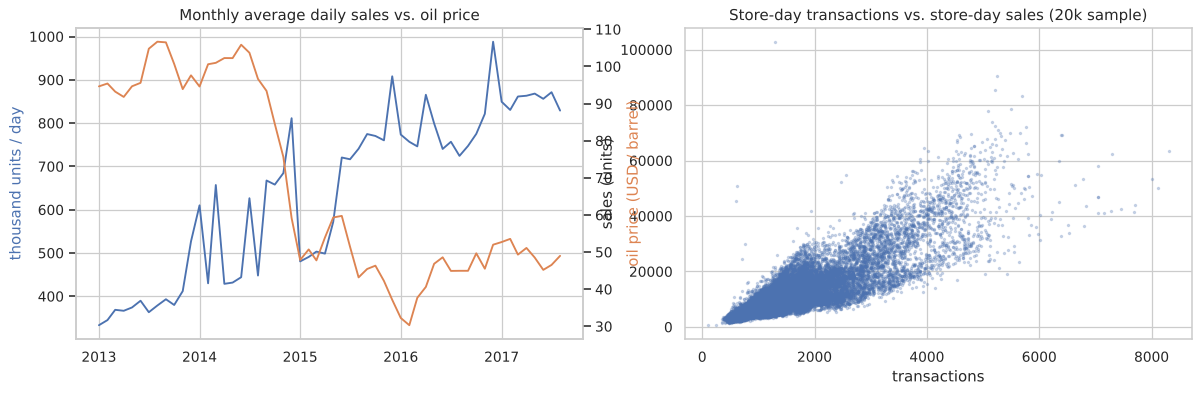

,correlation
monthly sales vs oil (Pearson),-0.7878
"monthly sales vs oil, 2015+ (Pearson)",-0.2177
store-day sales vs transactions (Pearson),0.8374
store-day sales vs transactions (Spearman),0.8175
"within-store corr, median across stores",0.5859


In [12]:
ext_corr = eda.oil_transactions(trm, raw, FIG_DIR); plt.show()
display(ext_corr)

**Findings: external variables**
* Monthly sales and oil prices correlate strongly *negatively* over the full history (r = −0.79), but only weakly since 2015 (r = −0.22). The full-history correlation mostly reflects two unrelated trends (sales growth and the 2014–15 oil collapse), so it is **not evidence of predictive value**.
* Transactions and sales are strongly related across store-days (Pearson 0.84, Spearman 0.82). Much of that comes from store size, and the median *within-store* correlation is 0.59. Future transactions are unknown, so only the version lagged 16+ days can be used.
* The ablation in Section 14 measures the predictive value of these lagged external features directly.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

## 7. EDA Findings and Interpretation

**Key EDA findings and what they changed in the pipeline:**

1. **Strong growth** (+49%, +15%, +20%, +8% per year) → train on recent history (from 2016) and rely on rolling-level features.
2. **Skewed, zero-inflated target** (31% zeros, skew 7.4) → `log1p` target (= RMSLE objective), plus a zero-forecast rule for series that have been inactive for 56 days.
3. **The weekly cycle dominates** (Sun 1.30 vs Thu 0.79 of trend) → lag 7, a same-weekday 4-week mean, day-of-week features, and strong seasonal baselines to beat.
4. **Volume is concentrated** (five families = 81% of units; 9× spread between stores) → report RMSLE *and* WAPE, and analyse errors by family and store.
5. **Intermittent families are the most volatile** (CV 2–3) → expect large relative errors there. This is a known limitation.
6. **Family-specific annual seasonality** (back-to-school for BOOKS and SCHOOL AND OFFICE SUPPLIES, December for FROZEN FOODS) → day-of-year features plus a 364-day rolling mean. The August test window falls in school season.
7. **Holidays and events matter but vary** (Additional days +21%, Jan 1 near zero, earthquake +21%) → transfer-aware national/regional/local flags.
8. **Promotions are strongly associated with sales** (monotone in intensity) but confounded with store and family size → promotion features plus an ablation test.
9. **Oil and transactions correlate with sales mainly through trends and store size** → used only with a lag of 16+ days and tested by ablation.
10. **Data quality is good overall.** The real risks are the many-to-many holiday join, missing Dec-25 dates and future-information leakage, and all three are handled explicitly.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

## 8. Data Preprocessing

`preprocess_data()` turns the long tables into a **wide panel** of shape (series × calendar days) that runs from 2013-01-01 to 2017-08-31:

* **Calendar re-indexing.** The four missing Dec-25 dates (stores closed) are inserted with `NaN` target. They are excluded from training, and the rolling statistics ignore NaN.
* **Target.** `ylog = log1p(sales)`. Test-period targets are `NaN` (unknown).
* **Oil.** Reindexed to every calendar day, forward-filled, then back-filled (only the first value, 2013-01-01, needs the back-fill).
* **Holidays.** Interpreted as described in Section 4, then aggregated to one flag per (date) for national holidays and one per (date, state/city) for regional/local holidays. Regional holidays are matched to the store's `state` and local holidays to its `city`. This removes the many-to-many join entirely.
* **Transactions.** A store × day array in which missing store-days stay `NaN`; tree models handle missing values natively.

No statistic is fitted on the full data here. The categorical encoders are fitted later, inside each model's pipeline, on training rows only.

In [13]:
t0 = time.time()
state = preprocess_data(raw)
print(f"Panel built in {time.time()-t0:.1f}s: {state.ylog.shape[0]} series x {state.ylog.shape[1]} days "
      f"({state.dates[0].date()} .. {state.dates[-1].date()})")
print("Closed (inserted) dates:", [d.date().isoformat() for d in state.closed_dates])
print("Known targets:", int((~np.isnan(state.ylog)).sum()), "== train rows:", len(raw["train"]))
assert int((~np.isnan(state.ylog)).sum()) == len(raw["train"]), "panel lost or duplicated train rows"
flag_counts = pd.Series({
    "national holiday days": int(state.date_flags["nat_is_holiday"].sum()),
    "national event days": int(state.date_flags["nat_is_event"].sum()),
    "work days (weekend made working)": int(state.date_flags["nat_is_workday"].sum()),
    "series-days with regional holiday": int(state.regional_flags.sum()),
    "series-days with local holiday": int(state.local_flags.sum()),
})
display(flag_counts.to_frame("count"))
print("Oil missing after fill:", int(state.oil.isna().sum()))

Panel built in 3.0s: 1782 series x 1704 days (2013-01-01 .. 2017-08-31)
Closed (inserted) dates: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']
Known targets: 3000888 == train rows: 3000888


,count
national holiday days,82
national event days,55
work days (weekend made working),5
series-days with regional holiday,1023
series-days with local holiday,11946


Oil missing after fill: 0


## 9. Feature Engineering

All features come from one function, `build_features(state, Y, dates, mode)`, which serves training, validation and test alike. History features are computed **per series**, chronologically, from the array `Y` that the caller passes in. When forecasting, `Y` has every value after the origin masked.

| Group | Features | Rationale | Availability / limitation |
|---|---|---|---|
| Sales history (recursive mode) | lag 1/7/14/28; rolling mean 7/14/28/56/364; rolling std 7/28; same-weekday mean of the last 4 weeks; share of zero days over 28 days | level, weekly pattern, volatility, intermittency | rolling windows end at **d-1** (current target excluded). Inside the horizon, values come from the model's own predictions |
| Sales history (direct mode) | lag 16/21/28/35; same rolling stats ending at **d-16** | known at the origin for every horizon day, so no recursion is needed | less recent information |
| Calendar | year, month, day, dow, doy, week, weekend, month start/end, sin/cos of dow and doy, payday | weekly and annual seasonality, payday effect | deterministic |
| Holiday / event | national holiday, event, work day, bridge, additional; regional & local holiday matched to the store | holiday spikes and closures | known in advance |
| Promotion | onpromotion, log1p, past 7/28-day promo mean, deviation from 28-day mean | promotions shift demand | current promo is given in test (planned) |
| External | oil lag 16, 28-day oil change (lag 16), store transactions lag 16, 28-day mean (lag 16) | macro conditions & store traffic | **lag ≥ 16 only**, because future values are unknown at the origin |
| Store / product | store_nbr, family, city, state, store type, cluster | level differences between groups | static |

In [14]:
for mode in ("recursive", "direct"):
    g = feature_groups(mode)
    print(f"[{mode}] {len(get_feature_columns(mode))} features:", {k: len(v) for k, v in g.items()})
folds = create_time_splits(state, TRAIN_START, n_folds=3)
f_last = folds[-1]
t0 = time.time()
X_demo = build_training_frame(state, TRAIN_START, f_last.origin, "recursive")
print(f"Training frame for {f_last.name}: {X_demo.shape} in {time.time()-t0:.1f}s, "
      f"{X_demo.memory_usage(deep=True).sum()/1e6:.0f} MB, dates {X_demo['date'].min().date()}..{X_demo['date'].max().date()}")
display(X_demo[X_demo["sid"] == 0].tail(3).T.head(25))

[recursive] 50 features: {'history (sales lags/rolling)': 13, 'calendar': 14, 'holiday/event': 8, 'promotion': 5, 'external (oil, transactions)': 4, 'store/product': 6}
[direct] 50 features: {'history (sales lags/rolling)': 13, 'calendar': 14, 'holiday/event': 8, 'promotion': 5, 'external (oil, transactions)': 4, 'store/product': 6}


Training frame for F3: (1026432, 53) in 1.9s, 207 MB, dates 2016-01-01..2017-07-30


,1021086,1022868,1024650
date,2017-07-28 00:00:00,2017-07-29 00:00:00,2017-07-30 00:00:00
sid,0,0,0
lag_1,1.7918,2.0794,1.6094
lag_7,2.3979,2.1972,0.0000
lag_14,1.6094,1.9459,1.0986
lag_28,2.4849,2.0794,1.6094
rmean_7,1.6418,1.5963,1.5124
rmean_14,1.5943,1.6279,1.6039
rmean_28,1.6169,1.6024,1.5856
rmean_56,1.5386,1.5223,1.5118


### 9.1 Leakage tests

These are automated checks, not just claims:
1. `lag_1` equals the previous day's actual value, and `rmean_7` excludes the current day.
2. **Perturbation test.** We replace every value after the origin with random noise. *Direct* features for all 16 horizon days must not change, and *recursive* features for horizon day 1 must not change. If any future value influenced the features, these assertions would fail.
3. The training frame of a fold contains no row after that fold's origin.

In [ ]:
        Yfull = state.ylog
s0, d0 = 10, state.date_idx("2017-07-20")
row = build_features(state, Yfull, [d0], "recursive").iloc[s0]
assert np.isclose(row["lag_1"], Yfull[s0, d0 - 1], equal_nan=True)
assert np.isclose(row["rmean_7"], np.nanmean(Yfull[s0, d0 - 7:d0]))
print("check 1 passed: lag_1 = y[d-1], rmean_7 = mean(y[d-7..d-1])")

o = state.date_idx(f_last.origin)
Y_masked = masked_history(state, f_last.origin)
Y_noise = state.ylog.copy(); rng = np.random.default_rng(0)
Y_noise[:, o + 1:] = rng.uniform(0, 10, size=Y_noise[:, o + 1:].shape)
hist_dir = history_cols("direct") + EXTERNAL_COLS
a = build_features(state, Y_masked, np.arange(o + 1, o + 17), "direct")[hist_dir]
b = build_features(state, Y_noise, np.arange(o + 1, o + 17), "direct")[hist_dir]
pd.testing.assert_frame_equal(a, b)
hist_rec = history_cols("recursive")
a1 = build_features(state, Y_masked, [o + 1], "recursive")[hist_rec]
b1 = build_features(state, Y_noise, [o + 1], "recursive")[hist_rec]
pd.testing.assert_frame_equal(a1, b1)
a2 = build_features(state, Y_masked, [o + 2], "recursive")["lag_1"]
b2 = build_features(state, Y_noise, [o + 2], "recursive")["lag_1"]
print("check 2 passed: direct features (16 days) and recursive day-1 features ignore post-origin values")
print(f"   (as expected, recursive lag_1 on day 2 depends on day 1: equal={a2.equals(b2)} -> must be filled by predictions)")
assert X_demo["date"].max() == f_last.origin and not X_demo["target"].isna().any()
print("check 3 passed: training frame ends at the origin and has no NaN targets")
del X_demo

check 1 passed: lag_1 = y[d-1], rmean_7 = mean(y[d-7..d-1])


check 2 passed: direct features (16 days) and recursive day-1 features ignore post-origin values
   (as expected, recursive lag_1 on day 2 depends on day 1: equal=False -> must be filled by predictions)
check 3 passed: training frame ends at the origin and has no NaN targets


## 10. Time-Series Validation

**Protocol:** expanding-window rolling origin with three folds of 16 days, ending on the last training date.

* **F1 (tuning).** Used *only* to choose hyper-parameters for the Decision Tree, Random Forest and XGBoost.
* **F2, F3 (evaluation).** Every model is scored on exactly these 32 dates. Their averages make up the model comparison.

For each fold, training rows run from `TRAIN_START` to the origin, and everything after the origin is masked before forecasting. This **simulates the real task**: on 2017-08-15 we must forecast 16 days ahead without seeing any of them.

* **Multi-step strategies.** *Recursive* models predict day 1, write the prediction into the history, rebuild lag/rolling features and predict day 2, and so on. *Direct* models use only features that are at least 16 days old, so all 16 days are predicted at once. A one-step-ahead score, which uses actual lags inside the window, is also shown later for contrast. It is optimistic and *not* a valid estimate for this task.
* **Early stopping for XGBoost** uses an *inner* hold-out: the last 16 days of the fold's training data, scored one-step. The model is then refit on all training rows with the selected number of trees. Validation targets are never used to fit or stop.
* **Preprocessing.** The ordinal encoders are fitted inside each pipeline on training rows only.
* **Zero-forecast rule** (applied identically to every ML model): a series with zero sales over the 56 days up to the origin is forecast as 0. It only uses data up to the origin.

,name,role,train_start,origin,val_start,val_end
0,F1,tuning,2016-01-01,2017-06-28,2017-06-29,2017-07-14
1,F2,evaluation,2016-01-01,2017-07-14,2017-07-15,2017-07-30
2,F3,evaluation,2016-01-01,2017-07-30,2017-07-31,2017-08-15
3,TEST,test,2016-01-01,2017-08-15,2017-08-16,2017-08-31


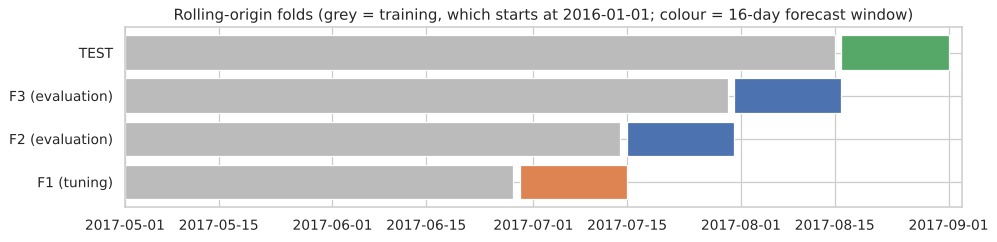

Zero-forecast rule at the F3 origin: 99 of 1782 series; their actual sales in the F3 window = 252.0 units


In [16]:
folds_df = pd.DataFrame([f.as_dict() for f in folds] + [test_fold(state, TRAIN_START).as_dict()])
display(folds_df)
TUNE_FOLDS = [f for f in folds if f.role == "tuning"]
EVAL_FOLDS = [f for f in folds if f.role == "evaluation"]
fig, ax = plt.subplots(figsize=(12, 2.6))
for i, f in enumerate(folds + [test_fold(state, TRAIN_START)]):
    ax.barh(i, (f.origin - pd.Timestamp("2017-05-01")).days, left=pd.Timestamp("2017-05-01"), color="#bbbbbb")
    ax.barh(i, 16, left=f.val_start, color={"tuning": "#DD8452", "evaluation": "#4C72B0", "test": "#55A868"}[f.role])
ax.set_yticks(range(4), [f"{f.name} ({f.role})" for f in folds] + ["TEST"])
ax.set_title(f"Rolling-origin folds (grey = training, which starts at {TRAIN_START}; colour = 16-day forecast window)")
ax.set_xlim(pd.Timestamp("2017-05-01"), pd.Timestamp("2017-09-03"))
fig.savefig(FIG_DIR / "12_validation_folds.png", bbox_inches="tight"); plt.show()

nz = zero_series_mask(state, f_last.origin)
print(f"Zero-forecast rule at the {f_last.name} origin: {nz.sum()} of {len(nz)} series; "
      f"their actual sales in the {f_last.name} window = {np.nansum(np.expm1(state.ylog[nz, o+1:o+17])):.1f} units")
cache = FrameCache(state, max_items=2)
log = ExperimentLog()
results = []        # per-fold metric tables of every model
val_preds = {}      # (model, fold) -> DataFrame(date, sid, actual, pred)
fitted = {}         # model name -> {fold: (model, info)}
MODEL_REGISTRY = {} # model name -> (fit_fn, mode) for the final refit

## 11. Baseline Forecasting
The baselines use only sales up to the origin and are scored on the same folds. A complex model is worth its cost only if it clearly beats these.

In [17]:
base_res, base_preds = train_baselines(state, folds, log)
results.append(base_res); val_preds.update(base_preds)
display(base_res.pivot_table(index="model", columns="fold", values=["RMSLE", "WAPE"]).round(4))

RMSLE                 WAPE              
fold                              F1     F2     F3     F1     F2     F3
model                                                                  
Day-of-week mean (last 4 wks) 0.4245 0.4427 0.5311 0.1345 0.1352 0.1760
Historical mean (28d)         0.4588 0.4688 0.5216 0.2465 0.2235 0.2081
Naive (last value)            0.6051 0.5881 0.6595 0.3031 0.2660 0.4442
Seasonal naive (t-7)          0.5176 0.5212 0.6170 0.1626 0.1397 0.2067

## 12. Decision Tree Modeling
The grid search over `max_depth` × `min_samples_leaf` runs on the **tuning fold F1** only. The best configuration is then scored on F2/F3.

In [18]:
from sklearn.tree import DecisionTreeRegressor
dt_rows = []
for params in DT_GRID:
    fn = lambda X, p=params: (fit_sklearn(DecisionTreeRegressor(random_state=RANDOM_STATE, **p), X, "recursive"), {})
    r, _, _ = run_model(f"DT {params}", fn, state, TUNE_FOLDS, cache, config=str(params), log=log)
    dt_rows.append({**params, **r.iloc[0][["RMSLE", "WAPE", "MAE", "train_time_s"]].to_dict()})
dt_tune = pd.DataFrame(dt_rows).sort_values("RMSLE"); display(dt_tune)
DT_BEST = {k: dt_tune.iloc[0][k] for k in DT_GRID[0]}
DT_BEST = {k: int(v) for k, v in DT_BEST.items()}
print("Selected DT params (F1):", DT_BEST)
dt_fit = lambda X: (fit_sklearn(DecisionTreeRegressor(random_state=RANDOM_STATE, **DT_BEST), X, "recursive"), {})
MODEL_REGISTRY["Decision Tree (tuned)"] = (dt_fit, "recursive")
r, p, m = run_model("Decision Tree (tuned)", dt_fit, state, EVAL_FOLDS, cache, config=str(DT_BEST), log=log, keep_models=True)
results.append(r); val_preds.update(p); fitted["Decision Tree (tuned)"] = m
dt_model = m[EVAL_FOLDS[-1].name][0]
imp = pd.Series(dt_model.named_steps["model"].feature_importances_, index=dt_model.named_steps["prep"].get_feature_names_out())
display(imp.sort_values(ascending=False).head(10).to_frame("DT impurity importance"))

  DT {'max_depth': 10, 'min_samples_leaf': 50} F1 (tuning    ) RMSLE=0.3930 WAPE=0.1268 MAE=61.47 fit=28s pred=4.4s


  DT {'max_depth': 10, 'min_samples_leaf': 200} F1 (tuning    ) RMSLE=0.3931 WAPE=0.1255 MAE=60.86 fit=28s pred=4.1s


  DT {'max_depth': 14, 'min_samples_leaf': 50} F1 (tuning    ) RMSLE=0.3897 WAPE=0.1266 MAE=61.39 fit=36s pred=4.1s


  DT {'max_depth': 14, 'min_samples_leaf': 200} F1 (tuning    ) RMSLE=0.3894 WAPE=0.1251 MAE=60.63 fit=35s pred=4.3s


  DT {'max_depth': 18, 'min_samples_leaf': 50} F1 (tuning    ) RMSLE=0.3949 WAPE=0.1291 MAE=62.57 fit=41s pred=4.5s


...

,max_depth,min_samples_leaf,RMSLE,WAPE,MAE,train_time_s
3,14,200,0.3894,0.1251,60.6317,35.3252
2,14,50,0.3897,0.1266,61.3878,36.1504
5,18,200,0.3906,0.1251,60.6658,37.3437
0,10,50,0.3930,0.1268,61.4710,27.5295
1,10,200,0.3931,0.1255,60.8624,27.5944
4,18,50,0.3949,0.1291,62.5745,40.6483


Selected DT params (F1): {'max_depth': 14, 'min_samples_leaf': 200}


  Decision Tree (tuned)              F2 (evaluation) RMSLE=0.4054 WAPE=0.1270 MAE=61.18 fit=35s pred=4.4s


  Decision Tree (tuned)              F3 (evaluation) RMSLE=0.4523 WAPE=0.1683 MAE=78.63 fit=36s pred=4.4s


,DT impurity importance
lag_7,0.8443
rmean_7,0.1033
dow_mean_4w,0.0369
rmean_56,0.0034
dayofyear,0.0031
rmean_14,0.0029
lag_1,0.0016
rstd_7,0.0009
promo_vs_28,0.0007
zero_share_28,0.0004


## 13. Random Forest Modeling
The Random Forest uses bootstrap row subsampling (`max_samples`) to bound memory and training time on ~1M rows with 2 CPU cores. Configurations are compared on F1 only.

In [19]:
from sklearn.ensemble import RandomForestRegressor
rf_rows = []
for params in RF_GRID:
    fn = lambda X, p=params: (fit_sklearn(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **p), X, "recursive"), {})
    r, _, _ = run_model(f"RF {params}", fn, state, TUNE_FOLDS, cache, config=str(params), log=log)
    rf_rows.append({**params, **r.iloc[0][["RMSLE", "WAPE", "MAE", "train_time_s"]].to_dict()})
rf_tune = pd.DataFrame(rf_rows).sort_values("RMSLE"); display(rf_tune)
RF_BEST = RF_GRID[int(np.argmin([row["RMSLE"] for row in rf_rows]))]
print("Selected RF params (F1):", RF_BEST)
rf_fit = lambda X: (fit_sklearn(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **RF_BEST), X, "recursive"), {})
MODEL_REGISTRY["Random Forest (tuned)"] = (rf_fit, "recursive")
r, p, m = run_model("Random Forest (tuned)", rf_fit, state, EVAL_FOLDS, cache, config=str(RF_BEST), log=log, keep_models=True)
results.append(r); val_preds.update(p); fitted["Random Forest (tuned)"] = m
rf_model = m[EVAL_FOLDS[-1].name][0]
imp = pd.Series(rf_model.named_steps["model"].feature_importances_, index=rf_model.named_steps["prep"].get_feature_names_out())
display(imp.sort_values(ascending=False).head(10).to_frame("RF impurity importance"))
del m, rf_model

  RF {'n_estimators': 100, 'max_depth': 18, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_samples': 0.15} F1 (tuning    ) RMSLE=0.3785 WAPE=0.1109 MAE=53.79 fit=126s pred=5.0s


  RF {'n_estimators': 100, 'max_depth': 24, 'min_samples_leaf': 10, 'max_features': 0.33, 'max_samples': 0.15} F1 (tuning    ) RMSLE=0.3772 WAPE=0.1091 MAE=52.90 fit=89s pred=5.5s


,n_estimators,max_depth,min_samples_leaf,max_features,max_samples,RMSLE,WAPE,MAE,train_time_s
1,100,24,10,0.3300,0.1500,0.3772,0.1091,52.8956,88.7565
0,100,18,20,0.5000,0.1500,0.3785,0.1109,53.7885,126.1188


Selected RF params (F1): {'n_estimators': 100, 'max_depth': 24, 'min_samples_leaf': 10, 'max_features': 0.33, 'max_samples': 0.15}


  Random Forest (tuned)              F2 (evaluation) RMSLE=0.3964 WAPE=0.1173 MAE=56.51 fit=95s pred=5.1s


  Random Forest (tuned)              F3 (evaluation) RMSLE=0.4392 WAPE=0.1524 MAE=71.20 fit=93s pred=5.3s


,RF impurity importance
lag_7,0.2840
rmean_7,0.2191
rmean_14,0.1675
rmean_28,0.1062
rmean_56,0.0505
dow_mean_4w,0.0502
lag_1,0.0495
lag_14,0.0285
lag_28,0.0118
zero_share_28,0.0070


## 14. XGBoost Modeling

XGBoost uses the `reg:squarederror` objective on `log1p(sales)`, which is equivalent to minimising RMSLE, with the `hist` tree method. The steps are:
1. **Baseline config** (close to defaults: depth 6, learning rate 0.1), scored on F2/F3.
2. **Random search** on the tuning fold F1 over `max_depth, learning_rate, subsample, colsample_bytree, min_child_weight, reg_alpha, reg_lambda`. `n_estimators` is chosen by early stopping on the inner hold-out. For speed, search candidates are *not* refit after early stopping.
3. **Tuned config**, scored on F2/F3 with refit.
4. **Direct (lag ≥ 16) variant** with the tuned params: one model for all 16 days, no recursion.
5. **Ablations** of the tuned recursive model without the promotion features and without the external (oil, transactions) features. These test whether those groups actually help.

In [20]:
XGB_BASE = dict(max_depth=6, learning_rate=0.1)
xgb_base_fit = lambda X: fit_xgboost(X, "recursive", XGB_BASE, max_rounds=XGB_MAX_ROUNDS, random_state=RANDOM_STATE, n_jobs=N_JOBS)
MODEL_REGISTRY["XGBoost (baseline config)"] = (xgb_base_fit, "recursive")
r, p, _ = run_model("XGBoost (baseline config)", xgb_base_fit, state, EVAL_FOLDS, cache, config=str(XGB_BASE), log=log)
results.append(r); val_preds.update(p)

  XGBoost (baseline config)          F2 (evaluation) RMSLE=0.3956 WAPE=0.1223 MAE=58.94 fit=105s pred=4.5s


  XGBoost (baseline config)          F3 (evaluation) RMSLE=0.4052 WAPE=0.1526 MAE=71.27 fit=76s pred=4.5s


In [21]:
space = dict(max_depth=[6, 8, 10], learning_rate=[0.08, 0.1, 0.15], subsample=[0.7, 0.85, 1.0],
             colsample_bytree=[0.5, 0.7, 0.9], min_child_weight=[1, 10, 50], reg_alpha=[0, 0.1, 1.0], reg_lambda=[1, 5, 20])
rng = np.random.default_rng(RANDOM_STATE)
candidates = [XGB_BASE | dict(subsample=1.0, colsample_bytree=1.0, min_child_weight=1, reg_alpha=0, reg_lambda=1)]
while len(candidates) < XGB_SEARCH_N:
    c = {k: v[int(rng.integers(len(v)))] for k, v in space.items()}
    if c not in candidates:
        candidates.append(c)
xgb_rows = []
for i, params in enumerate(candidates):
    fn = lambda X, p=params: fit_xgboost(X, "recursive", p, max_rounds=XGB_MAX_ROUNDS, refit=False,
                                         random_state=RANDOM_STATE, n_jobs=N_JOBS)
    r, _, _ = run_model(f"XGB search #{i}", fn, state, TUNE_FOLDS, cache, config=str(params), log=log)
    xgb_rows.append({**params, **r.iloc[0][["RMSLE", "WAPE", "MAE", "train_time_s"]].to_dict(), "config": r.iloc[0]["config"]})
xgb_tune = pd.DataFrame(xgb_rows).sort_values("RMSLE")
with pd.option_context("display.max_colwidth", 60):
    display(xgb_tune.drop(columns="config"))
XGB_TUNED = candidates[int(np.argmin([row["RMSLE"] for row in xgb_rows]))]
print("Selected XGBoost params (F1):", XGB_TUNED)
xgb_tune.to_csv(OUTPUT_DIR / "xgb_search_results.csv", index=False)

  XGB search #0                      F1 (tuning    ) RMSLE=0.3810 WAPE=0.1100 MAE=53.33 fit=82s pred=4.7s


  XGB search #1                      F1 (tuning    ) RMSLE=0.3816 WAPE=0.1116 MAE=54.09 fit=56s pred=4.4s


  XGB search #2                      F1 (tuning    ) RMSLE=0.3776 WAPE=0.1090 MAE=52.83 fit=52s pred=4.2s


  XGB search #3                      F1 (tuning    ) RMSLE=0.3768 WAPE=0.1106 MAE=53.62 fit=39s pred=4.6s


  XGB search #4                      F1 (tuning    ) RMSLE=0.3773 WAPE=0.1061 MAE=51.44 fit=71s pred=4.4s


  XGB search #5                      F1 (tuning    ) RMSLE=0.3778 WAPE=0.1133 MAE=54.94 fit=63s pred=4.2s


,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_alpha,reg_lambda,RMSLE,WAPE,MAE,train_time_s
3,10,0.1500,0.8500,0.5000,50,0.1000,5,0.3768,0.1106,53.6170,38.9294
4,8,0.0800,1.0000,0.9000,10,0.1000,20,0.3773,0.1061,51.4448,70.5653
2,10,0.0800,0.7000,0.7000,50,1.0000,20,0.3776,0.1090,52.8332,51.9651
5,8,0.1000,0.8500,0.5000,1,0.1000,20,0.3778,0.1133,54.9430,62.5784
0,6,0.1000,1.0000,1.0000,1,0.0000,1,0.3810,0.1100,53.3331,81.7123
1,6,0.1500,0.8500,0.7000,10,1.0000,1,0.3816,0.1116,54.0909,55.8769


Selected XGBoost params (F1): {'max_depth': 10, 'learning_rate': 0.15, 'subsample': 0.85, 'colsample_bytree': 0.5, 'min_child_weight': 50, 'reg_alpha': 0.1, 'reg_lambda': 5}


In [22]:
xgb_tuned_fit = lambda X: fit_xgboost(X, "recursive", XGB_TUNED, max_rounds=XGB_MAX_ROUNDS, random_state=RANDOM_STATE, n_jobs=N_JOBS)
MODEL_REGISTRY["XGBoost (tuned)"] = (xgb_tuned_fit, "recursive")
r, p, m = run_model("XGBoost (tuned)", xgb_tuned_fit, state, EVAL_FOLDS, cache, config=str(XGB_TUNED), log=log, keep_models=True)
results.append(r); val_preds.update(p); fitted["XGBoost (tuned)"] = m

xgb_direct_fit = lambda X: fit_xgboost(X, "direct", XGB_TUNED, max_rounds=XGB_MAX_ROUNDS, random_state=RANDOM_STATE, n_jobs=N_JOBS)
MODEL_REGISTRY["XGBoost direct lag>=16 (tuned)"] = (xgb_direct_fit, "direct")
r, p, _ = run_model("XGBoost direct lag>=16 (tuned)", xgb_direct_fit, state, EVAL_FOLDS, cache, mode="direct",
                    config=str(XGB_TUNED), log=log)
results.append(r); val_preds.update(p)

  XGBoost (tuned)                    F2 (evaluation) RMSLE=0.3914 WAPE=0.1221 MAE=58.80 fit=45s pred=4.2s


  XGBoost (tuned)                    F3 (evaluation) RMSLE=0.4057 WAPE=0.1517 MAE=70.85 fit=60s pred=4.3s


  XGBoost direct lag>=16 (tuned)     F2 (evaluation) RMSLE=0.4128 WAPE=0.1309 MAE=63.07 fit=63s pred=0.4s


  XGBoost direct lag>=16 (tuned)     F3 (evaluation) RMSLE=0.4130 WAPE=0.1533 MAE=71.60 fit=32s pred=0.4s


In [23]:
# One-step-ahead score (uses ACTUAL lags inside the window) - shown only to quantify how optimistic
# a non-recursive evaluation would be. Not used for model selection.
fL = EVAL_FOLDS[-1]
xgb_last = fitted["XGBoost (tuned)"][fL.name][0]
a, b = state.date_idx(fL.val_start), state.date_idx(fL.val_end)
X1 = build_features(state, state.ylog, np.arange(a, b + 1), "recursive")
one = actuals_for(state, fL).assign(pred=np.expm1(np.clip(xgb_last.predict(X1[get_feature_columns()]), 0, None)))
one.loc[one["sid"].isin(np.where(zero_series_mask(state, fL.origin))[0]), "pred"] = 0
ms = regression_metrics(one["actual"], one["pred"])
mr = regression_metrics(val_preds[("XGBoost (tuned)", fL.name)]["actual"], val_preds[("XGBoost (tuned)", fL.name)]["pred"])
display(pd.DataFrame([ms, mr], index=["one-step-ahead (actual lags; optimistic)", "recursive 16-day (valid protocol)"]))
del X1

,MAE,RMSE,RMSLE,WAPE,Bias
one-step-ahead (actual lags; optimistic),62.2822,219.8238,0.3825,0.1333,0.0229
recursive 16-day (valid protocol),70.8473,251.4448,0.4057,0.1517,0.0328


In [24]:
if RUN_ABLATIONS:
    for label, excl in [("XGBoost (tuned) - no promo features", [c for c in PROMO_COLS]),
                        ("XGBoost (tuned) - no oil/transactions", EXTERNAL_COLS)]:
        fn = lambda X, e=excl: fit_xgboost(X, "recursive", XGB_TUNED, max_rounds=XGB_MAX_ROUNDS, random_state=RANDOM_STATE,
                                           n_jobs=N_JOBS, exclude=e)
        MODEL_REGISTRY[label] = (fn, "recursive")
        r, p, _ = run_model(label, fn, state, EVAL_FOLDS, cache, config=f"{XGB_TUNED} exclude={excl}", log=log)
        r["family"] = "ablation"
        results.append(r); val_preds.update(p)
else:
    print("Ablations skipped in QUICK_TEST mode.")

  XGBoost (tuned) - no promo features F2 (evaluation) RMSLE=0.4055 WAPE=0.1220 MAE=58.76 fit=39s pred=4.3s


  XGBoost (tuned) - no promo features F3 (evaluation) RMSLE=0.4804 WAPE=0.1579 MAE=73.77 fit=34s pred=4.4s


  XGBoost (tuned) - no oil/transactions F2 (evaluation) RMSLE=0.3903 WAPE=0.1226 MAE=59.04 fit=46s pred=4.3s


  XGBoost (tuned) - no oil/transactions F3 (evaluation) RMSLE=0.4048 WAPE=0.1526 MAE=71.28 fit=51s pred=4.4s


## 15. AutoGluon Experiment

**Choice: AutoGluon Tabular, not TimeSeries.** AutoGluon TimeSeries needs PyTorch and its deep-learning extras, which were not installed in this environment (2 CPU cores, no GPU). It would also bring its own validation and feature logic. **AutoGluon Tabular** can be trained on *exactly the same leakage-safe features* and plugged into *the same recursive 16-day forecaster* on *the same folds*, so its result is directly comparable with the other models.

Setup: `presets="medium_quality"`, LightGBM (+ an extra-trees variant) and XGBoost learners with a weighted ensemble, no bagging or stacking. `tuning_data` is the chronological inner hold-out (last 16 training days), so there is no random split. There is a time limit per fold. The models AutoGluon picks depend partly on wall-clock time, so results can vary slightly between runs.

In [25]:
ag_available = importlib.util.find_spec("autogluon") is not None and importlib.util.find_spec("autogluon.tabular") is not None
if not RUN_AUTOGLUON:
    print("AutoGluon disabled in configuration.")
elif not ag_available:
    print("AutoGluon is not installed -> experiment skipped. Install with: pip install 'autogluon.tabular[lightgbm]' "
          "(requires a Python version supported by AutoGluon).")
else:
    import logging
    logging.getLogger("autogluon").setLevel(logging.ERROR)   # hides "torch not installed" notices (no NN models are requested)
    ag_fit = lambda X, tag="": fit_autogluon(X, "recursive", MODEL_DIR / f"autogluon_{tag or int(time.time())}",
                                             time_limit=AG_TIME_LIMIT, verbosity=0)
    MODEL_REGISTRY["AutoGluon Tabular"] = (ag_fit, "recursive")
    r, p, m = run_model("AutoGluon Tabular", ag_fit, state, EVAL_FOLDS, cache,
                        config=f"medium_quality, GBM+GBM_XT+XGB, time_limit={AG_TIME_LIMIT}s", log=log, keep_models=True)
    results.append(r); val_preds.update(p)
    for fname, (mdl, info) in m.items():
        print(f"Leaderboard {fname} (score = -RMSE on inner hold-out, log scale):")
        display(info["leaderboard"][["model", "score_val", "fit_time", "pred_time_val"]])
    del m

	Failed to import torch or check CUDA availability!Please ensure you have the correct version of PyTorch installed by running `pip install -U torch`


	Failed to import torch or check CUDA availability!Please ensure you have the correct version of PyTorch installed by running `pip install -U torch`


	Failed to import torch or check CUDA availability!Please ensure you have the correct version of PyTorch installed by running `pip install -U torch`


	Failed to import torch or check CUDA availability!Please ensure you have the correct version of PyTorch installed by running `pip install -U torch`


	Failed to import torch or check CUDA availability!Please ensure you have the correct version of PyTorch installed by running `pip install -U torch`


...

	Failed to import torch or check CUDA availability!Please ensure you have the correct version of PyTorch installed by running `pip install -U torch`


  AutoGluon Tabular                  F3 (evaluation) RMSLE=0.4023 WAPE=0.1498 MAE=69.96 fit=485s pred=15.7s
Leaderboard F2 (score = -RMSE on inner hold-out, log scale):


,model,score_val,fit_time,pred_time_val
0,WeightedEnsemble_L2,-0.3600,278.3708,4.9643
1,LightGBMXT,-0.3607,147.2053,2.6254
2,LightGBM,-0.3626,131.1488,2.3382
3,XGBoost,-0.3691,34.0293,0.1255


Leaderboard F3 (score = -RMSE on inner hold-out, log scale):


,model,score_val,fit_time,pred_time_val
0,WeightedEnsemble_L2,-0.3712,472.0584,8.3314
1,LightGBMXT,-0.3717,180.6659,3.6621
2,LightGBM,-0.3732,291.3776,4.6685


## 16. Model Evaluation and Comparison

**Metrics** (computed on the original sales scale over all series × 16 days × evaluation folds):
* **MAE** = mean |y − ŷ|: the average absolute error in units.
* **RMSE** = sqrt(mean (y − ŷ)²): penalises large errors, so it is dominated by high-volume series (GROCERY I, BEVERAGES…).
* **RMSLE** = sqrt(mean (log1p ŷ − log1p y)²): a relative error that treats small and large series more evenly. It is the competition metric. Negative predictions are clipped to 0, and there are no negative actuals.
* **WAPE** = Σ|y − ŷ| / Σ|y|: total absolute error as a share of total volume. It is undefined (reported as NaN) if total actual sales are 0, which never happens in our windows.
* **Bias** = Σ(ŷ − y) / Σy: positive means over-forecasting.

,model,family,val_from,val_to,folds,horizon_days,MAE,RMSE,RMSLE,RMSLE_std,WAPE,Bias,train_time_s,predict_time_s
0,XGBoost (tuned) - no oil/transactions,ablation,2017-07-15,2017-08-15,"F2,F3",16,65.1632,235.9242,0.3975,0.0103,0.1376,-0.0083,48,4.4
1,AutoGluon Tabular,ml,2017-07-15,2017-08-15,"F2,F3",16,64.2249,236.6876,0.3981,0.0059,0.1356,-0.0093,403,13.3
2,XGBoost (tuned),ml,2017-07-15,2017-08-15,"F2,F3",16,64.8253,238.1630,0.3986,0.0101,0.1369,-0.0054,52,4.2
3,XGBoost (baseline config),ml,2017-07-15,2017-08-15,"F2,F3",16,65.1058,237.2699,0.4004,0.0068,0.1375,-0.0088,90,4.5
4,XGBoost direct lag>=16 (tuned),ml,2017-07-15,2017-08-15,"F2,F3",16,67.3343,242.8037,0.4129,0.0001,0.1421,-0.0244,47,0.4
5,Random Forest (tuned),ml,2017-07-15,2017-08-15,"F2,F3",16,63.8545,232.1924,0.4178,0.0302,0.1349,-0.0083,94,5.2
6,Decision Tree (tuned),ml,2017-07-15,2017-08-15,"F2,F3",16,69.9034,255.1036,0.4289,0.0332,0.1477,-0.0078,35,4.4
7,XGBoost (tuned) - no promo features,ablation,2017-07-15,2017-08-15,"F2,F3",16,66.2659,241.0708,0.4430,0.0529,0.1399,-0.0110,37,4.3
8,Day-of-week mean (last 4 wks),baseline,2017-07-15,2017-08-15,"F2,F3",16,73.6739,260.0691,0.4869,0.0625,0.1556,0.0161,0,0.0
9,Historical mean (28d),baseline,2017-07-15,2017-08-15,"F2,F3",16,102.4438,347.4061,0.4952,0.0374,0.2158,0.0023,0,0.0


Per-fold detail:


RMSLE          WAPE       
fold                                      F2     F3     F2     F3
model                                                            
AutoGluon Tabular                     0.3939 0.4023 0.1214 0.1498
Day-of-week mean (last 4 wks)         0.4427 0.5311 0.1352 0.1760
Decision Tree (tuned)                 0.4054 0.4523 0.1270 0.1683
Historical mean (28d)                 0.4688 0.5216 0.2235 0.2081
Naive (last value)                    0.5881 0.6595 0.2660 0.4442
Random Forest (tuned)                 0.3964 0.4392 0.1173 0.1524
Seasonal naive (t-7)                  0.5212 0.6170 0.1397 0.2067
XGBoost (baseline config)             0.3956 0.4052 0.1223 0.1526
XGBoost (tuned)                       0.3914 0.4057 0.1221 0.1517
XGBoost (tuned) - no oil/transactions 0.3903 0.4048 0.1226 0.1526
XGBoost (tuned) - no promo features   0.4055 0.4804 0.1220 0.1579
XGBoost direct lag>=16 (tuned)        0.4128 0.4130 0.1309 0.1533

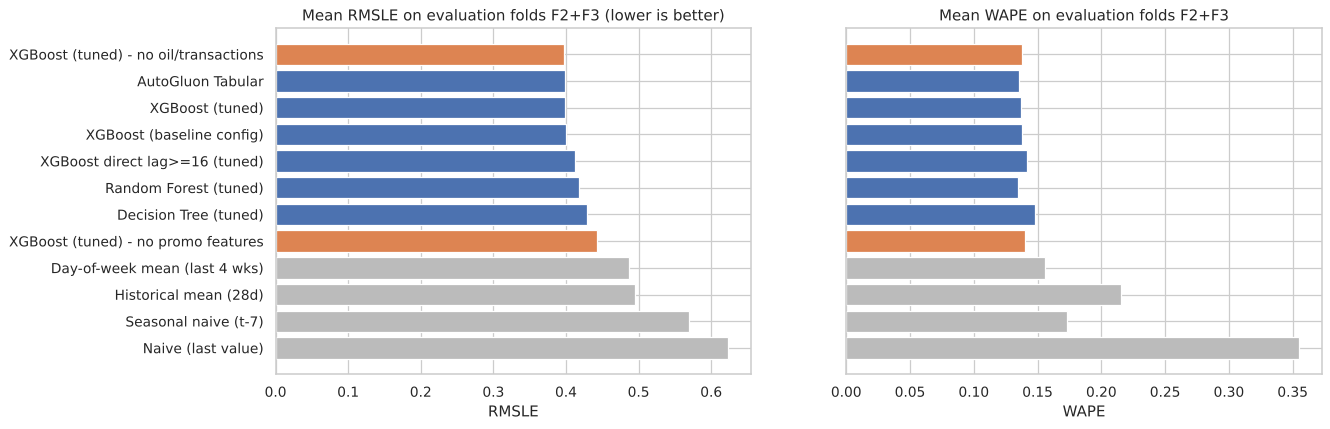

In [26]:
all_res = pd.concat(results, ignore_index=True)
all_res.to_csv(OUTPUT_DIR / "model_results_by_fold.csv", index=False)
comparison = compare_models(all_res)
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
show = comparison.drop(columns=["config"]).copy()
display(show.style.format({c: "{:.4f}" for c in ["MAE", "RMSE", "RMSLE", "RMSLE_std", "WAPE", "Bias"]} |
                          {"train_time_s": "{:.0f}", "predict_time_s": "{:.1f}"}).background_gradient(subset=["RMSLE", "WAPE"], cmap="RdYlGn_r"))
print("Per-fold detail:")
display(evaluate_models(all_res).pivot_table(index="model", columns="fold", values=["RMSLE", "WAPE"]).round(4))
log.frame().to_csv(OUTPUT_DIR / "experiment_log.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cmp = comparison.sort_values("RMSLE", ascending=False)
colors = cmp["family"].map({"baseline": "#bbbbbb", "ml": "#4C72B0", "ablation": "#DD8452"})
axes[0].barh(cmp["model"], cmp["RMSLE"], color=colors); axes[0].set(title="Mean RMSLE on evaluation folds F2+F3 (lower is better)", xlabel="RMSLE")
axes[1].barh(cmp["model"], cmp["WAPE"], color=colors); axes[1].set(title="Mean WAPE on evaluation folds F2+F3", xlabel="WAPE"); axes[1].set_yticklabels([])
fig.savefig(FIG_DIR / "13_model_comparison.png", bbox_inches="tight"); plt.show()

**Findings: model comparison** (mean of F2 2017-07-15..07-30 and F3 2017-07-31..08-15, 16-day recursive/direct forecasts)

| Model | RMSLE | WAPE | Note |
|---|---|---|---|
| AutoGluon Tabular | 0.3981 | 0.1356 | ~403 s fit per fold |
| **XGBoost (tuned)** | **0.3986** | 0.1369 | ~52 s fit per fold |
| XGBoost (baseline config) | 0.4004 | 0.1375 | |
| XGBoost direct lag ≥ 16 | 0.4129 | 0.1421 | no recursion, 10× faster prediction |
| Random Forest (tuned) | 0.4178 | 0.1349 | best WAPE/MAE/RMSE, weaker RMSLE |
| Decision Tree (tuned) | 0.4289 | 0.1477 | |
| Best baseline: day-of-week mean (4 wks) | 0.4869 | 0.1556 | |

* **Every ML model clearly beats every baseline.** XGBoost (tuned) improves RMSLE by 18% over the best baseline.
* **XGBoost tuning helped only a little** (0.4004 → 0.3986), and the gain is not consistent across folds. The tuned model is better on F2 (0.3914 vs 0.3956) but essentially tied on F3 (0.4057 vs 0.4052). The baseline configuration is already strong.
* **AutoGluon and XGBoost (tuned) are tied** (difference 0.0005 RMSLE, well within the fold-to-fold spread of ±0.006–0.010). AutoGluon costs about 8× the training time.
* **Random Forest has the best WAPE, MAE and RMSE but a worse RMSLE.** It is more accurate on high-volume series and less accurate, in relative terms, on small and intermittent ones. Model rankings depend on the metric, which is why several metrics are reported.
* **Recursive beats direct** (0.3986 vs 0.4129). Using the most recent days (lag 1–14), even through predictions, is worth more than the error that accumulates through recursion. The direct model under-forecasts more (bias −2.4% vs −0.5%).
* **The one-step-ahead evaluation is optimistic.** On F3, XGBoost scores RMSLE 0.3825 when actual lags are used, against 0.4057 under the valid 16-day recursive protocol. Evaluating with actual lags would overstate accuracy by about 6%.
* **Ablations.** Removing the **promotion** features hurts badly (RMSLE 0.3986 → 0.4430, with F3 going from 0.4057 to 0.4804), so promotions carry real predictive information. Removing the lagged **oil/transactions** features changes nothing meaningful (0.3975, slightly *better*). Those external features add no value at a lag of 16+ days.
* **F3 is harder than F2 for every model.** The F3 window contains the transferred national holiday (Primer Grito de Independencia, moved from Thu Aug 10 to **Fri Aug 11, 2017**) and the start-of-month/payday period.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

### 16.1 Diagnostics for the selected model (evaluation folds)
**Selection rule (fixed before looking at the test period):** pick the model with the lowest mean **RMSLE** on the evaluation folds F2 + F3. Ablation variants are not eligible, because they are diagnostics. If several models are within 0.002 RMSLE of the best, prefer the one with the lowest training time. Section 18 discusses the choice.

Selected model: XGBoost (tuned)  (models within 0.002 RMSLE of the best: ['AutoGluon Tabular', 'XGBoost (tuned)'])


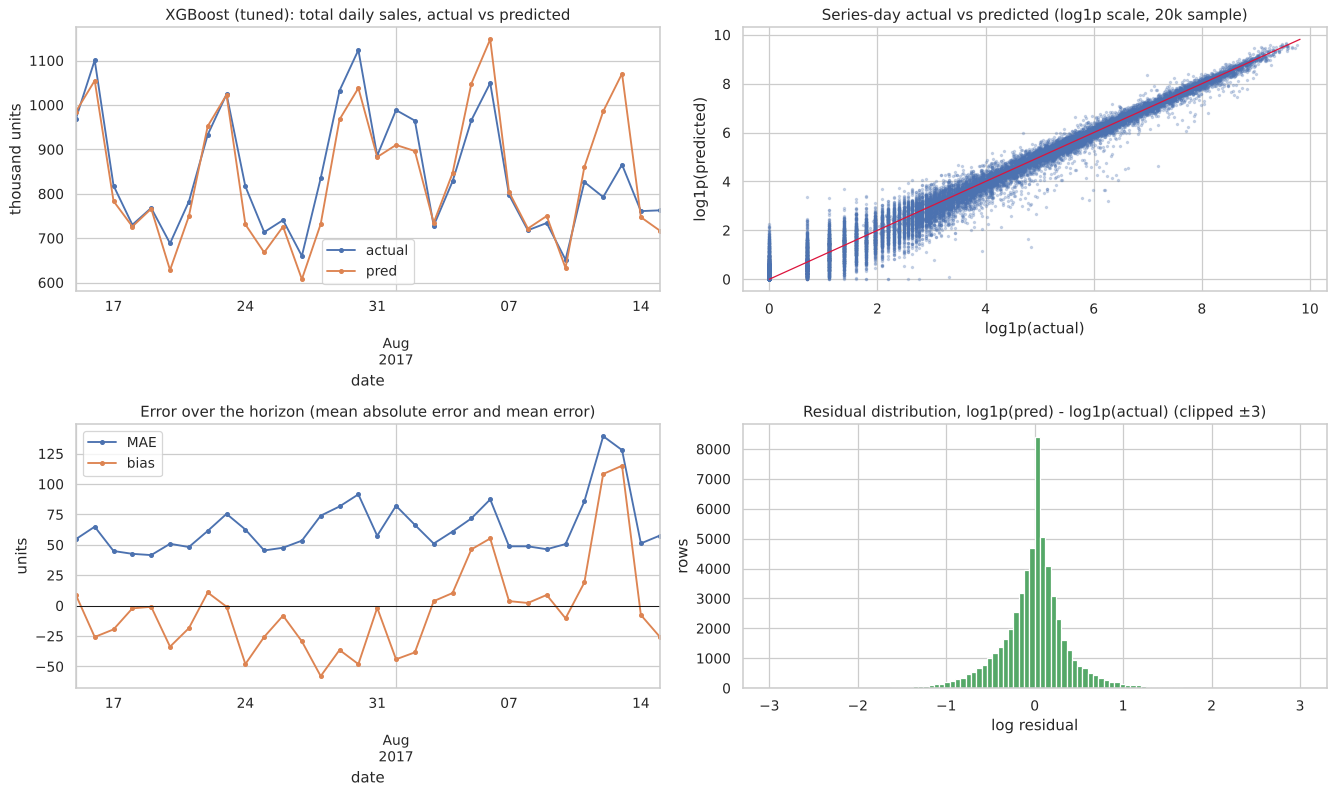

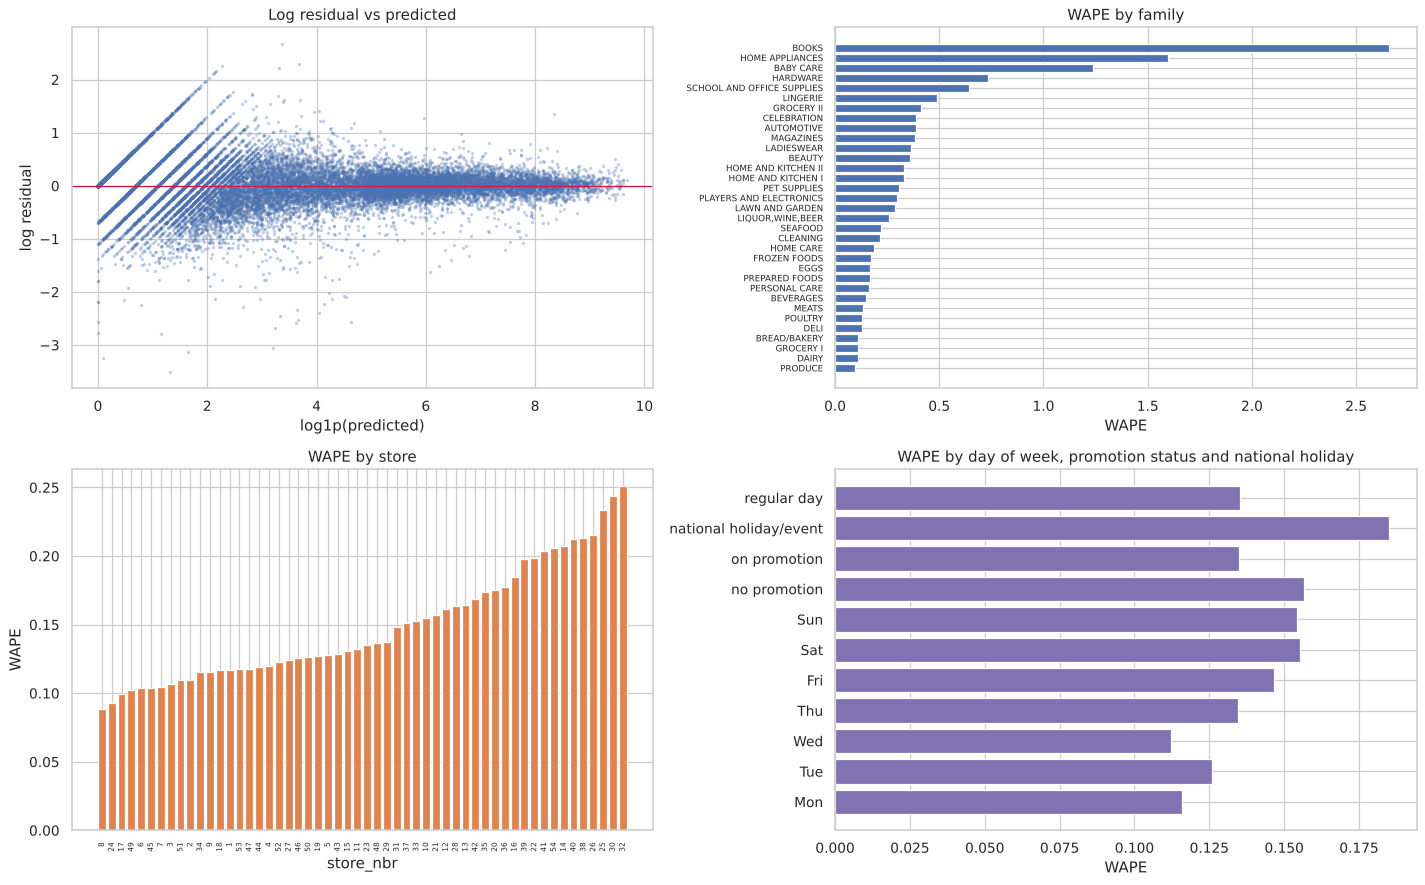

WAPE / bias by family (worst 8 by WAPE):


,WAPE,bias,sales
family,,,
BOOKS,2.6572,0.8745,30.0000
HOME APPLIANCES,1.5954,0.1926,439.0000
BABY CARE,1.2363,-0.2457,320.0000
HARDWARE,0.7330,-0.2915,"2,523.0000"
SCHOOL AND OFFICE SUPPLIES,0.6410,-0.5500,"57,898.0000"
LINGERIE,0.4872,-0.1827,"12,091.0000"
GROCERY II,0.4139,-0.1665,"57,970.0000"
CELEBRATION,0.3883,-0.1202,"22,730.0000"


Largest-volume families:


,WAPE,bias,sales
family,,,
GROCERY I,0.1103,-0.0067,"7,944,594.0000"
BEVERAGES,0.1494,-0.0338,"6,244,848.0000"
PRODUCE,0.0973,0.0312,"4,000,823.5000"
CLEANING,0.2149,-0.0179,"2,213,103.0000"
DAIRY,0.1098,0.0520,"1,474,726.0000"


,Mon,Tue,Wed,Thu,Fri,Sat,Sun,no promotion,on promotion,national holiday/event,regular day
WAPE,0.1158,0.1259,0.1122,0.1346,0.1465,0.1552,0.1543,0.1566,0.1350,0.1850,0.1351


Worst 5 stores:


,WAPE,bias
store_nbr,,
32,0.2508,-0.0952
30,0.2441,-0.0685
25,0.2335,-0.2133
26,0.2152,-0.0188
38,0.2132,-0.0200


In [27]:
eligible = comparison[comparison["family"] == "ml"].sort_values("RMSLE").reset_index(drop=True)
close = eligible[(eligible["RMSLE"] - eligible.iloc[0]["RMSLE"]) <= 0.002]
best = close.sort_values("train_time_s").iloc[0]
FINAL_MODEL = best_name = best["model"]
print(f"Selected model: {FINAL_MODEL}  (models within 0.002 RMSLE of the best: {close['model'].tolist()})")
best_val = pd.concat([val_preds[(best_name, f.name)] for f in EVAL_FOLDS], ignore_index=True)
best_val.to_csv(OUTPUT_DIR / "validation_predictions_best_model.csv", index=False)
diag = eda.diagnostics(best_val, state, raw, best_name, FIG_DIR); plt.show()
print("WAPE / bias by family (worst 8 by WAPE):"); display(diag["by_family"].sort_values("WAPE", ascending=False).head(8))
print("Largest-volume families:"); display(diag["by_family"].sort_values("sales", ascending=False).head(5))
display(diag["by_group"].T)
print("Worst 5 stores:"); display(diag["by_store"].sort_values("WAPE", ascending=False).head(5))

**Findings: diagnostics (XGBoost tuned, F2 + F3)**
* **Totals track well** on most days, and the residuals in log space are centred near 0 and roughly symmetric. Overall bias is −0.5%, so there is no systematic level bias.
* **The largest errors come on the long weekend of the transferred Aug 11 holiday.** The model forecast a normal Fri–Sun weekend spike (about 1.07M units on Sun Aug 13), but actual sales were much lower (about 0.86M). It also over-forecast Aug 5–6 and under-forecast late July. National holiday/event days have a WAPE of 0.185 vs. 0.135 on regular days. Weekends are harder (Sat/Sun ≈ 0.155) than Mon–Wed (≈ 0.11–0.13).
* **By family.** The big staples are accurate: GROCERY I WAPE 0.11, PRODUCE 0.10, DAIRY 0.11, BEVERAGES 0.15. Intermittent families have very large *relative* errors but tiny volume (BOOKS: 30 units in 32 days). **SCHOOL AND OFFICE SUPPLIES is under-forecast by 55%** (WAPE 0.64): its back-to-school ramp-up in late July and August is steeper than the history features expect.
* **By store.** WAPE ranges from about 0.08 to 0.25. The worst stores are 32, 30, 25, 26 and 38, all type C/D stores (three of them in Guayaquil). Store 25 (Salinas, a beach town) is under-forecast by 21%, which is consistent with seasonal tourism.
* **Rows with a promotion** are forecast more accurately (WAPE 0.135) than rows without one (0.157). Promoted rows are mostly high-volume items.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

## 17. Feature Importance and Explainability

We use XGBoost (tuned, F3 model) gain importance, the same importance aggregated by feature group, and SHAP values on a random sample of training rows. **Importance and SHAP describe what the model relies on (associations), not causal effects.**

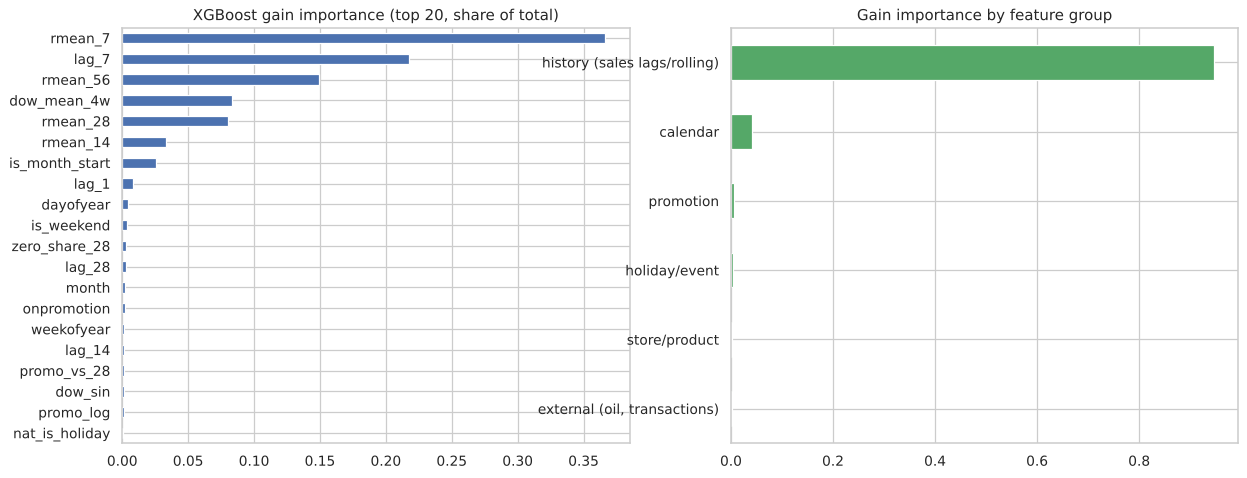

,gain share
history (sales lags/rolling),0.9468
calendar,0.0422
promotion,0.0050
holiday/event,0.0030
store/product,0.0017
"external (oil, transactions)",0.0012


In [28]:
xgb_pipe = fitted["XGBoost (tuned)"][EVAL_FOLDS[-1].name][0]
booster = xgb_pipe.named_steps["model"].get_booster()
gain = pd.Series(booster.get_score(importance_type="gain")).reindex(xgb_pipe.named_steps["prep"].get_feature_names_out()).fillna(0)
gain = gain / gain.sum()
groups = feature_groups("recursive")
grp_gain = pd.Series({g: gain.reindex(cols).sum() for g, cols in groups.items()}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
gain.sort_values().tail(20).plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set(title="XGBoost gain importance (top 20, share of total)")
grp_gain.plot.barh(ax=axes[1], color="#55A868"); axes[1].set(title="Gain importance by feature group")
fig.savefig(FIG_DIR / "14_xgb_feature_importance.png", bbox_inches="tight"); plt.show()
display(grp_gain.sort_values(ascending=False).to_frame("gain share"))
gain.sort_values(ascending=False).to_frame("gain_share").to_csv(OUTPUT_DIR / "xgb_feature_importance.csv")

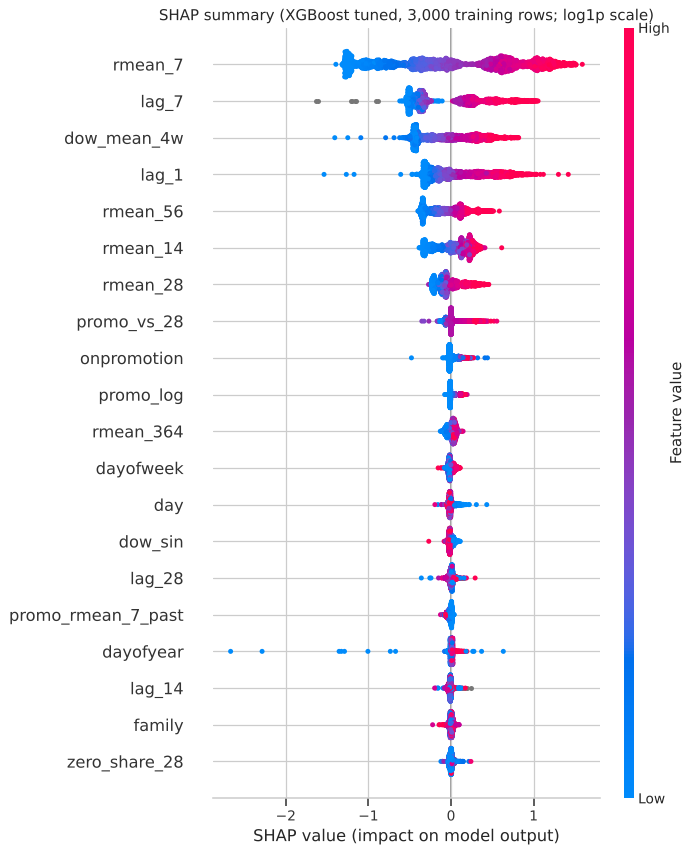

Example: store 46, BEVERAGES, 2017-01-08: base=3.475, prediction(log1p)=9.459, actual(log1p)=9.604


,SHAP contribution (log1p units),feature value
rmean_7,1.4361,7.7496
lag_1,1.3006,9.4013
rmean_14,0.6138,8.2778
dow_mean_4w,0.5343,6.1760
rmean_56,0.5140,8.6990
rmean_28,0.4535,8.5183
rstd_7,0.3642,3.1837
lag_28,0.2922,9.2645
onpromotion,0.1915,43.0000
promo_log,0.1353,3.7842


In [29]:
try:
    import shap
except ImportError as exc:
    shap = None
    print(f"SHAP not installed ({exc}); skipping SHAP plots. pip install shap")
if shap is not None:
    Xs = cache.get(EVAL_FOLDS[-1], "recursive").sample(3000, random_state=RANDOM_STATE)
    Xs_t = xgb_pipe.named_steps["prep"].transform(Xs[get_feature_columns()])
    explainer = shap.TreeExplainer(xgb_pipe.named_steps["model"])
    sv = explainer(Xs_t)
    plt.figure(); shap.summary_plot(sv.values, Xs_t, max_display=20, show=False)
    plt.title("SHAP summary (XGBoost tuned, 3,000 training rows; log1p scale)")
    plt.savefig(FIG_DIR / "15_shap_summary.png", bbox_inches="tight"); plt.show()
    # one individual prediction: largest-volume row in the sample
    i = int(np.argmax(Xs["target"].values))
    contrib = pd.Series(sv.values[i], index=Xs_t.columns).sort_values(key=np.abs, ascending=False).head(10)
    meta = state.series.iloc[int(Xs.iloc[i]["sid"])]
    print(f"Example: store {meta.store_nbr}, {meta.family}, {pd.Timestamp(Xs.iloc[i]['date']).date()}: "
          f"base={float(sv.base_values[i]):.3f}, prediction(log1p)={float(sv.base_values[i] + sv.values[i].sum()):.3f}, "
          f"actual(log1p)={Xs.iloc[i]['target']:.3f}")
    display(contrib.to_frame("SHAP contribution (log1p units)").join(Xs_t.iloc[i].rename("feature value")))

**Findings: explainability** (associations in the model, not causal effects)
* **Sales-history features dominate**, taking 94.7% of XGBoost gain: `rmean_7` (37%), `lag_7` (22%), `rmean_56`, `dow_mean_4w` and `rmean_28`. Calendar features account for 4.2% (mainly `is_month_start`, the payday/start-of-month effect, and day of year). Promotion, holiday, store and external features each account for under 1% of gain.
* **SHAP agrees.** Recent level (`rmean_7`, `lag_1`) and weekly position (`lag_7`, `dow_mean_4w`) move predictions by up to ±1.5 log units. `promo_vs_28` (promotion above the recent norm) and `onpromotion` push predictions up.
* **Gain importance understates promotions.** Promotion features have only 0.5% of gain, yet removing them raised RMSLE from 0.3986 to 0.4430. Much of their signal overlaps with the history features, and gain is shared among correlated predictors. Ablation is the better test of usefulness.
* **The low importance of oil/transactions (0.1%) matches the ablation**, which showed no gain from them.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

## 18. Final Model Selection

The rule from Section 16.1 is applied: lowest mean RMSLE on F2 + F3; within 0.002, choose the fastest to train.

In [30]:
best_baseline = comparison[comparison["family"] == "baseline"].iloc[0]
print(f"Selected: {FINAL_MODEL}  (RMSLE {best['RMSLE']:.4f}, WAPE {best['WAPE']:.4f}, mean fit {best['train_time_s']:.0f}s)")
print(f"Best baseline: {best_baseline['model']} (RMSLE {best_baseline['RMSLE']:.4f}, WAPE {best_baseline['WAPE']:.4f}) -> "
      f"relative RMSLE improvement {1 - best['RMSLE']/best_baseline['RMSLE']:.1%}")
display(eligible[["model", "RMSLE", "RMSLE_std", "WAPE", "MAE", "RMSE", "Bias", "train_time_s"]])

Selected: XGBoost (tuned)  (RMSLE 0.3986, WAPE 0.1369, mean fit 52s)
Best baseline: Day-of-week mean (last 4 wks) (RMSLE 0.4869, WAPE 0.1556) -> relative RMSLE improvement 18.1%


,model,RMSLE,RMSLE_std,WAPE,MAE,RMSE,Bias,train_time_s
0,AutoGluon Tabular,0.3981,0.0059,0.1356,64.2249,236.6876,-0.0093,403.4861
1,XGBoost (tuned),0.3986,0.0101,0.1369,64.8253,238.1630,-0.0054,52.2312
2,XGBoost (baseline config),0.4004,0.0068,0.1375,65.1058,237.2699,-0.0088,90.4252
3,XGBoost direct lag>=16 (tuned),0.4129,0.0001,0.1421,67.3343,242.8037,-0.0244,47.4225
4,Random Forest (tuned),0.4178,0.0302,0.1349,63.8545,232.1924,-0.0083,94.1613
5,Decision Tree (tuned),0.4289,0.0332,0.1477,69.9034,255.1036,-0.0078,35.3251


**Selected model: XGBoost (tuned), recursive 16-day forecasting.**
* AutoGluon had the numerically lowest RMSLE (0.3981 vs 0.3986). The gap of 0.0005 is far below the fold-to-fold standard deviation (0.006–0.010), and AutoGluon needs about 8× the training time (403 s vs 52 s per fold), more memory and a heavier dependency stack. The pre-registered tie rule therefore picks XGBoost.
* XGBoost (tuned) is also the more **stable** choice: its bias is small (−0.5%), its single-file pipeline (2.6 MB) is easy to deploy, and it comes with clear explainability (gain and SHAP).
* The "no oil/transactions" ablation scored 0.3975. It is not eligible under the rule (ablations are diagnostics), but it suggests the external features could simply be dropped in a future iteration with no loss.
* Final hyper-parameters (chosen on F1): `max_depth=10, learning_rate=0.15, subsample=0.85, colsample_bytree=0.5, min_child_weight=50, reg_alpha=0.1, reg_lambda=5`. Early stopping on the final fit picked **220 trees**.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

## 19. Final Training
The selected configuration is refit with the same feature pipeline on **all rows from `TRAIN_START` to 2017-08-15**. For XGBoost, early stopping again uses the last 16 days, and the model is then refit on everything.

In [31]:
final_fit_fn, final_mode = MODEL_REGISTRY[FINAL_MODEL]
tf_ = test_fold(state, TRAIN_START)
cache = None; import gc; gc.collect()     # free fold frames before the final fit
t0 = time.time()
X_final = build_training_frame(state, TRAIN_START, tf_.origin, final_mode)
final_model, final_info = final_fit_fn(X_final)
final_train_time = time.time() - t0
print(f"Final model '{FINAL_MODEL}' trained on {len(X_final):,} rows "
      f"({X_final['date'].min().date()}..{X_final['date'].max().date()}) in {final_train_time:.0f}s")
print({k: v for k, v in (final_info or {}).items() if np.isscalar(v)})

Final model 'XGBoost (tuned)' trained on 1,054,944 rows (2016-01-01..2017-08-15) in 83s
{'best_iteration': 220, 'inner_rmse_log': 0.37638702691847853, 'refit_on_full_train': True}


## 20. Test Forecast Generation
We forecast 2017-08-16 to 2017-08-31 from the 2017-08-15 origin with the same forecaster used in validation (recursive or direct, plus the zero rule). Test targets are unknown in the panel.

Forecast generated in 4.3s: (28512, 2)


,id,sales
0,3000888,3.8652
1,3000889,0.0000
2,3000890,4.4511
3,3000891,"2,185.5623"
4,3000892,0.0649


,count,mean,std,min,25%,50%,75%,max
sales,"28,512.0000",437.2976,"1,179.9423",0.0000,3.5587,28.1109,257.6415,"14,825.0527"


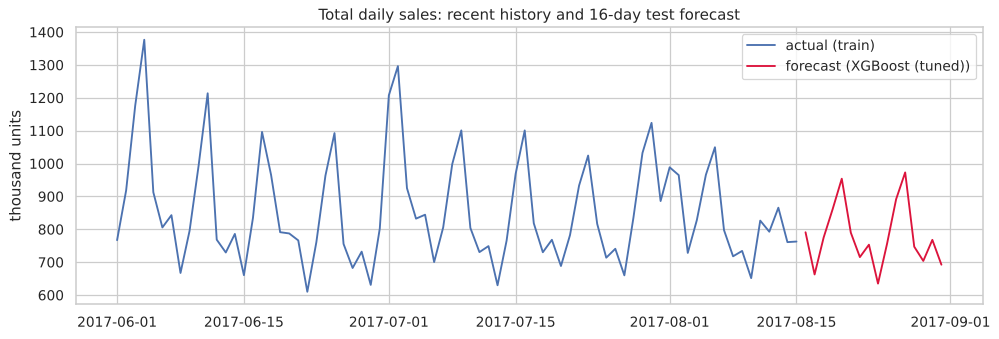

Mean daily total: last 16 train days 832,449 vs forecast 779,264


In [32]:
t0 = time.time()
submission = generate_predictions(final_model, state, mode=final_mode)
print(f"Forecast generated in {time.time()-t0:.1f}s: {submission.shape}")
display(submission.head()); display(submission["sales"].describe().to_frame().T)
hist = raw["train"].groupby("date")["sales"].sum().loc["2017-06-01":]
fc = raw["test"][["id", "date"]].merge(submission, on="id").groupby("date")["sales"].sum()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(hist.index, hist / 1e3, label="actual (train)"); ax.plot(fc.index, fc / 1e3, label=f"forecast ({FINAL_MODEL})", color="crimson")
ax.set(title="Total daily sales: recent history and 16-day test forecast", ylabel="thousand units"); ax.legend()
fig.savefig(FIG_DIR / "16_test_forecast_total.png", bbox_inches="tight"); plt.show()
print(f"Mean daily total: last 16 train days {hist.iloc[-16:].mean():,.0f} vs forecast {fc.mean():,.0f}")

## 21. Submission Validation
`validate_submission()` raises an error if any check fails.

In [33]:
checks = validate_submission(submission, raw["sample_submission"])
display(checks)
sub_path = OUTPUT_DIR / "submission.csv"
submission.to_csv(sub_path, index=False)
reread = pd.read_csv(sub_path)
validate_submission(reread, raw["sample_submission"])
print(f"Saved and re-validated {sub_path} ({len(reread):,} rows)")

,check,passed
0,"columns == ['id','sales']",True
1,same columns as sample,True
2,row count == 28512,True
3,id sequence identical to sample (same order),True
4,ids unique,True
5,no missing sales,True
6,all sales finite,True
7,sales numeric,True
8,sales non-negative,True


Saved and re-validated /home/claude/store-sales-forecasting/outputs/submission.csv (28,512 rows)


## 22. Model Persistence
We save the fitted pipeline with joblib, plus a metadata JSON holding the feature mode and columns, dates, hyper-parameters and package versions. Then we reload it and check that it reproduces the predictions.

In [34]:
final_params = {"Decision Tree (tuned)": DT_BEST, "Random Forest (tuned)": RF_BEST}.get(FINAL_MODEL, XGB_TUNED if "XGBoost" in FINAL_MODEL else None)
meta = dict(model_name=FINAL_MODEL, feature_mode=final_mode, feature_columns=get_feature_columns(final_mode),
            target="log1p(sales)", horizon=HORIZON, train_start=TRAIN_START, train_end=str(state.train_end.date()),
            params=final_params, fit_info={k: v for k, v in (final_info or {}).items() if np.isscalar(v)},
            zero_rule_days=56, folds=[f.as_dict() for f in folds], quick_test=QUICK_TEST,
            validation=comparison.set_index("model").loc[FINAL_MODEL, ["RMSLE", "WAPE", "MAE", "RMSE"]].to_dict(),
            metric_definitions="MAE, RMSE, RMSLE (preds clipped >=0), WAPE=sum|e|/sum y, on original scale")
paths = save_artifacts(final_model, meta, MODEL_DIR)
print(paths)
if "model" in paths:
    import joblib
    reloaded = joblib.load(paths["model"])
    sub2 = generate_predictions(reloaded, state, mode=final_mode)
    assert np.allclose(sub2["sales"].values, submission["sales"].values), "reloaded model gives different predictions"
    print("Reloaded model reproduces the submission exactly.")
json.dump({"versions": versions, "quick_test": QUICK_TEST, "train_start": TRAIN_START,
           "dt_best": DT_BEST, "rf_best": RF_BEST, "xgb_base": XGB_BASE, "xgb_tuned": XGB_TUNED,
           "final_model": FINAL_MODEL, "runtime_min": (time.time() - RUN_T0) / 60},
          open(OUTPUT_DIR / "run_config.json", "w"), indent=2, default=str)
print(f"Total notebook runtime so far: {(time.time()-RUN_T0)/60:.1f} min")

{'model': '/home/claude/store-sales-forecasting/models/final_model.joblib', 'metadata': '/home/claude/store-sales-forecasting/models/final_model_metadata.json'}


Reloaded model reproduces the submission exactly.
Total notebook runtime so far: 44.9 min


In [35]:
expected = ["data_quality_report.csv", "model_comparison.csv", "model_results_by_fold.csv", "experiment_log.csv",
            "submission.csv", "validation_predictions_best_model.csv", "run_config.json"]
status = pd.DataFrame({"file": expected, "exists": [(OUTPUT_DIR / f).exists() for f in expected]})
display(status)
print("Figures:", len(list(FIG_DIR.glob("*.png"))), "PNG files in", FIG_DIR)
assert status["exists"].all()

,file,exists
0,data_quality_report.csv,True
1,model_comparison.csv,True
2,model_results_by_fold.csv,True
3,experiment_log.csv,True
4,submission.csv,True
5,validation_predictions_best_model.csv,True
6,run_config.json,True


Figures: 18 PNG files in /home/claude/store-sales-forecasting/outputs/figures


## 23. Business Recommendations

These recommendations come from the validated model and the EDA. They are associations, so they should be confirmed with controlled tests before money is committed.

1. **Inventory planning by weekday.** Demand on Saturdays and Sundays runs about 22–30% above trend, and Thursdays about 20% below. Schedule replenishment and staffing so shelves are full before the weekend. The model forecasts the weekly shape well (Mon–Wed WAPE ≈ 0.11–0.13).
2. **Hold safety stock where the forecast is weakest, not uniformly.** Staples (GROCERY I, PRODUCE, DAIRY: WAPE ≈ 0.10–0.11) can run lean. Intermittent and seasonal families (SCHOOL AND OFFICE SUPPLIES, BOOKS, BABY CARE, HOME APPLIANCES, HARDWARE) need higher safety stock or a judgement overlay. **For the late-August test window**, school supplies were under-forecast by 55% in validation, so planners should add an explicit back-to-school uplift.
3. **Holiday and long-weekend overrides.** The largest errors came on the transferred-holiday long weekend (Aug 11–13, 2017), when demand was lower than a normal weekend. Planners should review forecasts by hand for transferred holidays and bridge days, and the forecasting team should add holiday-specific history (see Future research).
4. **Promotions.** Promotion information is the most valuable non-history signal: removing it raised RMSLE by 11%. Planned promotions should be fed into the forecast **as early as possible**, and the promotion calendar should be kept accurate. The causal uplift (which differs widely by family: GROCERY I ×4.2 vs PRODUCE ×1.2 in raw ratios) should be measured with A/B or holdout-store tests before promotion budgets are reallocated.
5. **Store focus.** Small type C/D stores and the seasonal beach store 25 have the highest relative error. A local review of these stores, or store-specific seasonal features, offers the best return.
6. **Keep the pipeline simple.** Oil prices and lagged transactions added nothing at forecast time and can be dropped, which removes two data feeds. Retrain weekly, because the model relies mainly on the most recent weeks of sales.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>

## 24. Limitations and Future Research

**Limitations**
* **Only two evaluation folds** (32 days, July–August 2017). The ranking between close models (AutoGluon, XGBoost tuned/baseline) is not statistically separable, and results may differ in other seasons, such as December.
* **Hyper-parameter search was small.** It used 6 XGBoost candidates and 2 RF configurations on a single tuning fold, constrained by 2 CPU cores. To save time, XGBoost search candidates were not refit after early stopping, while the evaluated models were.
* **Recursive training mismatch.** The model is trained on actual lags but predicts with its own predictions inside the horizon (exposure bias). Errors can accumulate over the 16 days.
* **Training window** starts in 2016-01-01, a period that includes the earthquake. Longer or shorter windows were not compared.
* **Holiday handling is generic.** There is one flag per type, so the model cannot learn that a particular holiday, or a transferred long weekend, behaves differently.
* **The zero-forecast rule** (56 days with no sales → 0) will miss series that restart. In validation these series sold only 252 units in 16 days.
* **AutoGluon** was run as Tabular, not TimeSeries (no PyTorch), with a 480 s time limit per fold. Its results depend on wall-clock time.
* `is_payday` comes from the competition description, not the data files.
* Feature importance and SHAP describe model behaviour, not causal effects.

**Future research**
1. More folds (e.g. 8–12 rolling origins across a full year) and paired significance tests between models.
2. A hybrid **direct/recursive** strategy, or one model per horizon bucket, to reduce error accumulation, plus horizon-aware training (e.g. training with lags taken from earlier predictions).
3. Holiday-specific features: holiday name, days to/from the holiday, long-weekend indicators, and last year's sales on the same holiday (`lag_364` around events).
4. Family-level or hierarchical models and reconciliation (store × family → store → total), plus Tweedie or Poisson objectives for intermittent families.
5. Promotion features with more structure: future promotion counts within the horizon, promotion share across the store/family, and the store's total promotions.
6. LightGBM/CatBoost and AutoGluon TimeSeries (with PyTorch available) compared on the same protocol, plus simple ensembling of XGBoost, AutoGluon and RF, which have different error profiles (RF wins on WAPE, XGBoost on RMSLE).
7. Prediction intervals (quantile objectives or conformal prediction) to set safety stock directly.

<sub>Written after executing the notebook in FULL mode (TRAIN_START = 2016-01-01). Numbers quoted here come from the outputs above. Re-runs reproduce DT/RF/XGBoost exactly; AutoGluon can differ slightly because it trains under a time limit.</sub>